# Classical and Bayesian estimation of multicomponent stress-strength reliability

## DA2141 project 3

**Vaidik Maheshwari (250150045)** and **Anant Gupta (250150004)**

**Assigned topic:** Classical and Bayesian estimation of multicomponent stress-strength reliability under block progressive hybrid censoring and k-record for Weibull distribution.

This project derives and implements a common-shape Weibull model, unrestricted and order-restricted maximum likelihood estimates, a dependent gamma-Dirichlet joint prior, unrestricted and order-restricted Bayesian estimates, interval estimation, a 48-scenario Monte Carlo experiment, and a reproducible application to published jute-fibre measurements. All estimates and figures are computed from the stated likelihood. The assigned spreadsheet's row 3 supplies the five mandatory requirements.


Run all cells in order from this project folder. The notebook retains computed outputs and exports results, figures and datasets. The default execution performs every simulation and validation rather than loading unverified example numbers. Python cells contain no comments.

| Requirement | Where it is fulfilled |
|---|---|
| Unrestricted and restricted MLEs | Sections 5-6; implemented profile fits and real-data/Monte Carlo tables |
| Joint Bayesian priors | Sections 7-8; dependent gamma-Dirichlet prior with a_0=2 and c_1+c_2=4 |
| Unrestricted and ordered Bayesian estimates | Support-specific quadrature, posterior means, LINEX, credible intervals and checked sampling |
| Complete simulation study | 48 scenarios, 300 replications each, all four estimators, parameter/reliability errors, interval coverage and MCSEs |
| Suitable-data validation | Published 15 mm/20 mm jute groups, calibrated fit checks, retained observations, inference, sensitivity and predictive checks |

## 1. Model, notation and assumptions

There are $K$ independent component strengths $X_1,\ldots,X_K$ and a single stress $Y$ shared by the components. The system works if at least s components exceed Y. All strengths are identically distributed and independent of Y. Strength observations used for estimation come from independent blocks drawn from this same population; a block is a testing facility, not an extra component in the system. We use $K=5$ and $s=3$ for the main experiment. The record order $k$ is different from the number of components $K$.

For a positive variable Z, the rate parameterization of the Weibull distribution is

$$f(z;\alpha,\lambda)=\alpha\lambda z^{\alpha-1}\exp(-\lambda z^\alpha),\qquad F(z)=1-\exp(-\lambda z^\alpha).$$

Thus

$$S(z)=\exp(-\lambda z^\alpha),\quad h(z)=\alpha\lambda z^{\alpha-1},\quad F^{-1}(u)=\left(\frac{-\log(1-u)}{\lambda}\right)^{1/\alpha}.$$

The conventional Weibull scale is $\eta=\lambda^{-1/\alpha}$. Calling $\lambda$ a rate avoids reversing the stochastic ordering. We assume $X\sim\operatorname{Weibull}(\alpha,a)$ and $Y\sim\operatorname{Weibull}(\alpha,b)$, with $\alpha,a,b>0$. Their common shape yields a tractable reliability formula and is checked on the complete application data. Under the increasing transformation $z\mapsto z^\alpha$, strengths become exponential with rate $a$ and stress becomes exponential with rate $b$.

The natural engineering restriction is $a\le b$: strength has larger survival at every positive threshold. Equivalently, $\eta_X\ge\eta_Y$. This restriction is an assumption about populations, not a conclusion automatically established by the data. Simulation deliberately includes $a>b$ to quantify the effect of imposing a false restriction.


## 2. Reliability derivation

Conditional on $Y=y$, the number of components surviving is binomial with success probability $S_X(y)$. The conditional binomial probability must be integrated over the common stress:

$$R_{s,K}=\int_0^\infty\sum_{j=s}^{K}\binom{K}{j}S_X(y)^j[1-S_X(y)]^{K-j}f_Y(y)\,dy.$$

Set $\rho=b/a$ and $u=\exp(-ay^\alpha)$. The transformed stress density satisfies

$$f_Y(y)\,dy=-\rho u^{\rho-1}\,du.$$

$$R_{s,K}=\rho\sum_{j=s}^{K}\binom{K}{j}\int_0^1u^{\rho+j-1}(1-u)^{K-j}\,du=\rho\sum_{j=s}^{K}\binom{K}{j}B(\rho+j,K-j+1).$$

An equivalent and more stable expression follows from exponential order statistics. At least s strengths exceed stress exactly when $Y^\alpha$ is below the $(K-s+1)$-th smallest transformed strength. That order statistic is the sum of independent exponentials with rates $Ka,(K-1)a,\ldots,sa$. Its Laplace transform at $b$ is the product of $ja/(ja+b)$. Therefore

$$R_{s,K}=1-\prod_{j=s}^{K}\frac{j}{j+\rho}.$$

Useful limiting checks are

$$R_{1,1}=\frac{b}{a+b},\qquad R_{K,K}=\frac{b}{Ka+b},$$

$$\lim_{\rho\to0}R_{s,K}=0,\qquad\lim_{\rho\to\infty}R_{s,K}=1.$$ Reliability decreases as $s$ increases. For fixed $a$ and $b$, reliability is independent of the common shape $\alpha$. The shape still affects rate estimates through the likelihood. For $s=3$, $K=5$ and $a=b$,

$$R_{3,5}=1-\frac34\frac45\frac56=\frac12.$$

The common stress makes component success indicators dependent after $Y$ is integrated out:

$$\operatorname{Cov}(I[X_i>Y],I[X_j>Y])=\frac{b}{b+2a}-\left(\frac{b}{b+a}\right)^2>0.$$

Consequently replacing $S_X(y)$ by $P(X>Y)$ in the conditional binomial sum computes a different model. This project uses the shared-stress integral rather than the unconditional binomial expression in equations (2.5)-(2.7) of Newer (2025).

For stable numerical evaluation,

$$R=-\operatorname{expm1}\left(-\sum_{j=s}^{K}\log(1+\rho/j)\right).$$


## 3. Strength sampling: block progressive hybrid censoring

In block $i$, $n_i$ specimens start together. A target $m_i$, threshold $T_i$ and planned withdrawal vector $(R_{i1},\ldots,R_{im_i})$ are specified before testing, with $\sum_jR_{ij}=n_i-m_i$. At observed failure $x_{ij}$, the prescribed number of survivors is selected uniformly for withdrawal. Withdrawals are noninformative and block assignment is random.

The principal Type-I scheme stops at $\tau_i=\min(x_{im_i},T_i)$. If the target is reached before $T_i$, all remaining survivors are withdrawn at the last failure. Otherwise $d_i<m_i$ failures are observed. Using the realized withdrawal counts $r_{ij}$, the number of terminal survivors is

$$q_i=n_i-d_i-\sum_{j=1}^{d_i}r_{ij}.$$ The block likelihood, up to design factors independent of the model parameters, is

$$L_i\propto\prod_{j=1}^{d_i}f_X(x_{ij})S_X(x_{ij})^{r_{ij}}S_X(\tau_i)^{q_i}.$$

Here $q_i=0$ when the target is reached because final survivors are already included in $r_{i,d_i}$. There is no double-counting of final withdrawals. A block with zero failures still contributes its terminal survival factor.

The adaptive Type-II alternative matches the main reference's design. It guarantees $m_i$ failures: intermediate withdrawals at failures after $T_i$ are canceled, and all survivors are withdrawn at the final target failure. Its duration may exceed $T_i$. Its likelihood uses the same expression with $d_i=m_i$, $q_i=0$ and the actual adapted counts $r_{ij}$. The notebook separately implements both protocols and records specimen counts and stopping outcomes.

Multiplying independent block likelihoods gives

$$L_X\propto\alpha^d a^d\exp\left[(\alpha-1)\sum_{i,j}\log x_{ij}-a A(\alpha)\right],$$

$$d=\sum_i d_i,\qquad A(\alpha)=\sum_{i,j}(1+r_{ij})x_{ij}^{\alpha}+\sum_i q_i\tau_i^{\alpha}.$$

Scheduled removals after termination contribute nothing. The specimen-conservation check is $n_i=d_i+\sum_jr_{ij}+q_i$. Exposure is the sum of transformed failure times and transformed right-censoring times for every starting unit.


## 4. Stress sampling: upper k-record values

Starting with the first $k$ independent stress observations, record the $k$-th largest, which is their minimum. Subsequently a record transition occurs whenever a new observation exceeds the current k-th largest; after updating the largest k observations, retain their new minimum. Collect exactly $r$ successive records $y_1<\cdots<y_r$ and stop at the final prescribed record. Original table positions in the application are an artificial acquisition sequence, not historical timestamps.

On the cumulative-hazard scale $H_Y(y)=-\log S_Y(y)$, the successive k-record increments are independent exponential variables with rate $k$. One justification is that the k surviving exceedances above the current threshold have independent exponential residual hazards; their next minimum has rate k. The joint density on the hazard scale is $k^r\exp[-kH_Y(y_r)]$ over the ordered region. Transforming back using $H_Y^{\prime}(y)=h_Y(y)$ gives

$$L_Y=k^r\exp[-kH_Y(y_r)]\prod_{j=1}^{r}h_Y(y_j)=k^r S_Y(y_r)^k\prod_{j=1}^{r}\frac{f_Y(y_j)}{S_Y(y_j)}.$$

For Weibull observations,

$$L_Y\propto\alpha^r b^r\exp\left[(\alpha-1)\sum_{j=1}^{r}\log y_j-b B(\alpha)\right],\qquad B(\alpha)=k y_r^{\alpha}.$$

The records are dependent and are never treated as an independent Weibull sample. Simulation uses

$$y_j=\left(\frac{\sum_{l=1}^{j}E_l}{kb}\right)^{1/\alpha},\qquad E_l\overset{\mathrm{iid}}{\sim}\operatorname{Exp}(1).$$ Record waiting times are not included in this marginal likelihood. The notebook retains acquisition positions for audit only. Including waiting times requires a different joint likelihood; the inter-record expression in the main reference is not copied into this marginal analysis.


## 5. Joint likelihood and maximum likelihood estimates

Define $q=d+r$ and

$$C=\sum_{i,j}\log x_{ij}+\sum_{j=1}^{r}\log y_j.$$ The parameter-dependent log-likelihood is

$$\ell(\alpha,a,b)=q\log\alpha+d\log a+r\log b+(\alpha-1)C-aA(\alpha)-bB(\alpha).$$

The score equations are

$$\ell_a=d/a-A(\alpha),\quad\ell_b=r/b-B(\alpha),\quad\ell_\alpha=q/\alpha+C-aA'(\alpha)-bB'(\alpha).$$

For fixed $\alpha$, the unique positive rate estimates are

$$\widehat a(\alpha)=\frac{d}{A(\alpha)},\qquad\widehat b(\alpha)=\frac{r}{B(\alpha)}.$$ The unrestricted shape estimate maximizes

$$\ell_p(\alpha)=q\log\alpha-d\log A(\alpha)-r\log B(\alpha)+(\alpha-1)C+\text{constant}.$$

The profile score is

$$\ell_p^{\prime}(\alpha)=\frac{q}{\alpha}+C-d\frac{A^{\prime}(\alpha)}{A(\alpha)}-r\frac{B^{\prime}(\alpha)}{B(\alpha)}.$$

Write $A(\alpha)=\sum_lw_l\exp(\alpha\log z_l)$. The second derivative of $\log A$ is the weighted variance of $\log z_l$, with weights proportional to $w_lz_l^\alpha$. Since $\log B$ is linear in $\alpha$,

$$\ell_p''(\alpha)=-q/\alpha^2-d\operatorname{Var}_{w_lz_l^\alpha/A}(\log z_l)<0.$$

Distinct records ensure a finite interior maximum: the score diverges positively near zero and is negative eventually because the largest record is larger than earlier records. This proof assumes $d>0$ and $r\ge2$. If $d=0$, the unrestricted strength-rate supremum can occur at $a=0$; the software reports this instead of presenting a finite interior MLE. All delivered experiments meet the stated conditions.

For fixed $\alpha$ under $a\le b$, either the unrestricted pair satisfies the order or the optimum lies on the boundary. On the boundary $a=b=\lambda$, differentiation yields $\lambda=q/(A+B)$. Therefore

$$ (\widetilde a,\widetilde b)=\begin{cases}(d/A,r/B),&d/A\le r/B,\\(q/(A+B),q/(A+B)),&d/A>r/B.\end{cases}$$

Reoptimize $\alpha$ with this pair at every trial shape. Simply sorting the unrestricted estimates, or pooling at the unrestricted shape without reoptimization, is not the restricted MLE. On the pooled branch, the second derivative is

$$\ell_{p,O}^{\prime\prime}(\alpha)=-\frac{q}{\alpha^2}-q\frac{d^2}{d\alpha^2}\log[A(\alpha)+B(\alpha)]<0.$$

The score agrees across a pooling transition. This gives a unique profile maximum under the same conditions. Reliability estimates follow by invariance:

$$\widehat R=R(\widehat a,\widehat b),\qquad\widetilde R=R(\widetilde a,\widetilde b).$$


## 6. Observed information and intervals

Differentiate exposures directly:

$$A'=\sum_lw_lz_l^\alpha\log z_l,\quad A''=\sum_lw_lz_l^\alpha(\log z_l)^2,\quad B'=B\log y_r,\quad B''=B(\log y_r)^2.$$

The negative Hessian in the parameter order $(\alpha,a,b)$ is

$$I=\begin{pmatrix}q/\alpha^2+aA''+bB''&A'&B'\\A'&d/a^2&0\\B'&0&r/b^2\end{pmatrix}.$$

At an unrestricted MLE, the covariance approximation is

$$V=I(\widehat\alpha,\widehat a,\widehat b)^{-1}.$$

For parameter $\theta_j$, a positive 95% confidence interval is

$$\left[\exp\left(\log\widehat\theta_j-1.96\frac{\sqrt{V_{jj}}}{\widehat\theta_j}\right),\quad\exp\left(\log\widehat\theta_j+1.96\frac{\sqrt{V_{jj}}}{\widehat\theta_j}\right)\right].$$

For the log-rate ratio, define

$$\psi=\log\rho=\log b-\log a,\qquad g=\left(0,-\frac1a,\frac1b\right)^{\mathsf T}.$$

Its estimated standard error and ratio endpoints are

$$\operatorname{SE}(\widehat\psi)=\sqrt{g^{\mathsf T}Vg},$$

$$\rho_{\mathrm L}=\exp[\widehat\psi-1.96\operatorname{SE}(\widehat\psi)],$$

$$\rho_{\mathrm U}=\exp[\widehat\psi+1.96\operatorname{SE}(\widehat\psi)].$$

Transform through the increasing reliability function:

$$[R(1,\rho_{\mathrm L}),\ R(1,\rho_{\mathrm U})].$$

This construction keeps parameter endpoints positive and reliability endpoints between zero and one.


A normal approximation at a pooled restricted MLE is nonregular. The application instead reports percentile parametric bootstrap intervals, regenerating complete strength blocks, withdrawals, hybrid stopping and stress k-records under the fitted model and refitting each replicate. Bootstrap intervals at an order boundary can have point mass at $R=1/2$; they are descriptive finite-sample approximations, not a claim of exact boundary coverage. Their simulation coverage is assessed separately. Bayesian intervals are posterior credible intervals and have a different interpretation from confidence intervals.


## 7. Dependent joint prior and its derivation

Use $t=a+b$ and $p=a/(a+b)$. Independently assign

$$t\sim\operatorname{Gamma}(a_0,b_0),\quad p\sim\operatorname{Beta}(c_1,c_2),\quad\alpha\sim\operatorname{Gamma}(a_1,b_1),$$

where Gamma is shape-rate. The absolute Jacobian from $(t,p)$ to $(a,b)$ is $t$. The rate-pair density is

$$\pi(a,b)=\frac{b_0^{a_0}\Gamma(c_1+c_2)}{\Gamma(a_0)\Gamma(c_1)\Gamma(c_2)}e^{-b_0(a+b)}(a+b)^{a_0-c_1-c_2}a^{c_1-1}b^{c_2-1}.$$

This is the two-dimensional gamma-Dirichlet family used in Sultana et al. It gives independent Gamma rates only if $a_0=c_1+c_2$. The primary choice is

$$(a_0,b_0,c_1,c_2,a_1,b_1)=(2,0.5,2,2,2,1).$$

Since $a_0\ne c_1+c_2$, dependence is genuine. For $c=c_1+c_2$,

$$E(a)=\frac{a_0c_1}{b_0c},\quad E(b)=\frac{a_0c_2}{b_0c},\quad\operatorname{Cov}(a,b)=\frac{a_0c_1c_2(c-a_0)}{b_0^2c^2(c+1)}.$$

Here prior means of both rates are 2, prior mean shape is 2, and covariance is 0.8. These are fixed choices rather than hyperparameters fitted to each simulation's true parameters. They are proper, moderately broad priors, not literally noninformative. Prior sensitivity is reported and the application does not recycle the same data into a prior presented as external information.

For the order-restricted model condition this prior on $p\le1/2$:

$$\pi_O(\alpha,a,b)=\pi(\alpha,a,b)\frac{I(a\le b)}{P(p\le1/2)},\qquad P(p\le1/2)=I_{1/2}(c_1,c_2).$$

With symmetric $c_1=c_2=2$ the normalizing probability is 1/2. This is a truncated dependent joint prior; sorting draws from a posterior with labelled strength and stress roles would target a different posterior.


## 8. Posterior, Bayesian estimators and computation

In the original coordinates the posterior kernel is

$$\pi(\alpha,a,b\mid D)\propto\alpha^{q+a_1-1}e^{(\alpha-1)C-b_1\alpha}a^{d+c_1-1}b^{r+c_2-1}(a+b)^{a_0-c_1-c_2}e^{-a(A+b_0)-b(B+b_0)}.$$

In $(\alpha,t,p)$, including the Jacobian,

$$\pi(\alpha,t,p\mid D)\propto\alpha^{q+a_1-1}e^{(\alpha-1)C-b_1\alpha}p^{d+c_1-1}(1-p)^{r+c_2-1}t^{q+a_0-1}e^{-tH},$$

$$H=b_0+pA(\alpha)+(1-p)B(\alpha).$$

Hence $t\mid\alpha,p,D\sim\operatorname{Gamma}(q+a_0,H)$. Integrating t exactly gives

$$\pi(\alpha,p\mid D)\propto\alpha^{q+a_1-1}e^{(\alpha-1)C-b_1\alpha}p^{d+c_1-1}(1-p)^{r+c_2-1}H^{-(q+a_0)}.$$

The unrestricted support is $\alpha>0$, $0<p<1$; the restricted support is $\alpha>0$, $0<p\le1/2$. Two-dimensional Gauss-Legendre quadrature integrates $\log\alpha$ from $\log(0.02)$ to $\log(30)$ and p on its model support. The $\exp(\log\alpha)$ Jacobian is included, and weights are normalized with log-sum-exp. Tail weights and refinement comparisons check truncation and discretization. Simulation uses 80 by 110 nodes, whereas the application uses 240 by 320 and a denser refinement. These numerical bounds are integration settings; edge-mass checks assess whether they materially truncate the posterior.

The conditional moments are

$$E(t\mid\alpha,p,D)=\frac{q+a_0}{H},$$

$$E(t^2\mid\alpha,p,D)=\frac{(q+a_0)(q+a_0+1)}{H^2}.$$

Consequently, the posterior rate means are

$$E(a\mid D)=E\left[\frac{p(q+a_0)}{H}\,\middle|\,D\right],$$

$$E(b\mid D)=E\left[\frac{(1-p)(q+a_0)}{H}\,\middle|\,D\right].$$

The posterior mean shape follows directly from the normalized quadrature weights.


Under squared error loss, the Bayes reliability estimate is the posterior mean of R itself:

$$\widehat R_B=E[R(p,1-p)\mid D].$$

It is generally different from evaluating R at posterior mean rates. Under LINEX loss

$$L(\delta,R)=\exp[c(\delta-R)]-c(\delta-R)-1,$$

Differentiating posterior expected loss gives

$$\widehat R_{B,c}=-\frac1c\log E[e^{-cR}\mid D],\qquad c\ne0.$$

The notebook reports $c=+1.5$ and $c=-1.5$, equal-tail 95% credible intervals, and shortest weighted 95% intervals for R. Shortest intervals are numerical approximations to HPD intervals for a unimodal marginal; equal-tail and shortest intervals are not interchangeable.

For an independent computational check, four Metropolis-Hastings chains sample the collapsed density in $(\log\alpha,\operatorname{logit}v)$, where $p=v$ for the unrestricted model and $p=v/2$ for the restricted model. The transformed target includes the log-shape Jacobian and

$$\log\left(\frac{dp}{dz}\right)=\log p_{\max}+\log v+\log(1-v).$$

Symmetric Gaussian random-walk proposals use a mode-based covariance fixed before sampling. Given each accepted state, t is drawn from its exact conditional Gamma distribution. Each chain uses 15,000 steps with 4,000 discarded warm-up steps; no adaptation occurs in the retained samples. Trace plots, density plots, split R-hat, effective sample sizes, and Monte Carlo standard errors accompany comparisons against quadrature. These diagnostics are classical split variance R-hat and an initial monotone autocorrelation ESS, not rank-normalized diagnostics.


## 9. Executable implementation
The following cell contains the complete implementation, including the censoring protocols, record likelihood, profile MLEs, dependent prior, posterior integration, bootstrap and numerical diagnostics.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, special, stats, integrate
from numpy.polynomial.legendre import leggauss
from IPython.display import display, Markdown

ROOT = Path.cwd()
for directory in ['data', 'results', 'figures', 'reports']:
    (ROOT / directory).mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.2})
SEED = 250150045
PRIOR = dict(a0=2.0, b0=0.5, c1=2.0, c2=2.0, a1=2.0, b1=1.0)
PARAMETERS = ['alpha', 'lambda_X', 'lambda_Y', 'R_3_5']


def save_figure(name):
    plt.savefig(ROOT / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.savefig(ROOT / 'figures' / (name + '.pdf'), bbox_inches='tight')
    plt.show()
    plt.close()


def reliability(a, b, s=3, K=5):
    rho = np.asarray(b) / np.asarray(a)
    return -np.expm1(sum(-np.log1p(rho / j) for j in range(s, K + 1)))


def removal_plan(n, m, pattern='balanced'):
    plan = np.zeros(m, dtype=int)
    if pattern == 'late':
        plan[-1] = n - m
    else:
        for i in range(n - m):
            plan[i % max(m - 1, 1)] += 1
    return plan


def censor_block(values, m, T, plan, rng, mode='typeI'):
    active = np.arange(len(values))
    failures, removed = [], []
    terminal, terminal_count = 0.0, 0
    case = 'target'
    for j in range(m):
        selected = active[np.argmin(values[active])]
        failure = float(values[selected])
        if mode == 'typeI' and failure > T:
            terminal, terminal_count, case = float(T), len(active), 'time'
            break
        active = active[active != selected]
        failures.append(failure)
        if j == m - 1:
            r = len(active)
        elif mode == 'adaptiveII' and failure > T:
            r = 0
        else:
            r = min(int(plan[j]), len(active))
        if r:
            withdrawn = rng.choice(active, r, replace=False)
            active = active[~np.isin(active, withdrawn)]
        removed.append(r)
        terminal = failure
    x = np.asarray(failures)
    R = np.asarray(removed, dtype=int)
    exposure_x = np.r_[x, terminal] if terminal_count else x.copy()
    exposure_w = np.r_[1 + R, terminal_count] if terminal_count else 1 + R
    assert len(x) + int(R.sum()) + terminal_count == len(values)
    return dict(x=x, R=R, terminal=terminal, terminal_count=terminal_count, z=exposure_x, w=exposure_w, n=len(values), m=m, T=T, mode=mode, case=case)


def make_data(blocks, records, k):
    x = np.concatenate([b['x'] for b in blocks])
    z = np.concatenate([b['z'] for b in blocks])
    w = np.concatenate([b['w'] for b in blocks])
    y = np.asarray(records)
    if len(x) == 0 or len(y) < 2:
        raise ValueError('A finite joint MLE requires strength failures and at least two distinct records.')
    if np.any(z <= 0) or np.any(y <= 0) or np.any(np.diff(y) <= 0):
        raise ValueError('Positive observations and strictly increasing records are required.')
    return dict(blocks=blocks, x=x, z=z, w=w, y=y, k=k, d=len(x), r=len(y), C=np.log(x).sum() + np.log(y).sum(), lx=np.log(z), ly=np.log(y), q=len(x) + len(y))


def exposures(alpha, data):
    vals = data['w'] * np.exp(alpha * data['lx'])
    A = vals.sum()
    B = data['k'] * np.exp(alpha * data['ly'][-1])
    return A, B


def loglik(theta, data):
    alpha, a, b = theta
    if min(theta) <= 0:
        return -np.inf
    A, B = exposures(alpha, data)
    return data['q'] * np.log(alpha) + data['d'] * np.log(a) + data['r'] * np.log(b) + (alpha - 1) * data['C'] - a * A - b * B


def conditional_rates(alpha, data, restricted=False):
    A, B = exposures(alpha, data)
    a, b = data['d'] / A, data['r'] / B
    if restricted and a > b:
        a = b = data['q'] / (A + B)
    return a, b


def fit_mle(data, restricted=False):
    def objective(logalpha):
        alpha = np.exp(logalpha)
        a, b = conditional_rates(alpha, data, restricted)
        return -loglik((alpha, a, b), data)
    fit = optimize.minimize_scalar(objective, bounds=(np.log(0.02), np.log(30)), method='bounded', options={'xatol': 1e-10})
    if not fit.success:
        raise RuntimeError(fit.message)
    alpha = np.exp(fit.x)
    if alpha < .021 or alpha > 29:
        raise RuntimeError('Shape optimizer reached its search boundary.')
    a, b = conditional_rates(alpha, data, restricted)
    return np.array([alpha, a, b])


def observed_information(theta, data):
    alpha, a, b = theta
    v = data['w'] * np.exp(alpha * data['lx'])
    Ap, App = np.sum(v * data['lx']), np.sum(v * data['lx'] ** 2)
    B = data['k'] * np.exp(alpha * data['ly'][-1])
    Bp, Bpp = B * data['ly'][-1], B * data['ly'][-1] ** 2
    return np.array([[data['q'] / alpha ** 2 + a * App + b * Bpp, Ap, Bp], [Ap, data['d'] / a ** 2, 0], [Bp, 0, data['r'] / b ** 2]])


def asymptotic_intervals(theta, data):
    covariance = np.linalg.inv(observed_information(theta, data))
    if np.any(np.linalg.eigvalsh(covariance) <= 0):
        raise RuntimeError('Observed information is not positive definite.')
    parameter_ci = np.exp(np.log(theta)[:, None] + np.array([-1, 1]) * stats.norm.ppf(.975) * np.sqrt(np.diag(covariance))[:, None] / theta[:, None])
    grad = np.array([0., -1 / theta[1], 1 / theta[2]])
    se = np.sqrt(grad @ covariance @ grad)
    rho_ci = np.exp(np.log(theta[2] / theta[1]) + np.array([-1, 1]) * stats.norm.ppf(.975) * se)
    return parameter_ci, reliability(np.ones(2), rho_ci)


def weighted_quantile(values, weights, probs=(.025, .975)):
    order = np.argsort(values)
    v, w = np.asarray(values)[order], np.asarray(weights)[order]
    total = w.sum()
    cw = (np.cumsum(w) - 0.5 * w) / total
    return np.interp(probs, cw, v)


def shortest_interval(values, weights, mass=.95):
    order = np.argsort(values)
    v, w = np.asarray(values)[order], np.asarray(weights)[order]
    cum = np.r_[0, np.cumsum(w) / np.sum(w)]
    ends = np.searchsorted(cum, cum[:-1] + mass)
    good = ends <= len(v)
    starts = np.arange(len(v))[good]
    ends = np.minimum(ends[good] - 1, len(v) - 1)
    j = np.argmin(v[ends] - v[starts])
    return np.array([v[starts[j]], v[ends[j]]])


_QUADRATURE = {}


def posterior_grid(data, restricted=False, prior=None, na=110, np_=160):
    pr = PRIOR if prior is None else prior
    key = (na, np_, restricted)
    if key not in _QUADRATURE:
        ea, wa = leggauss(na)
        ep, wp = leggauss(np_)
        lo, hi = np.log(.02), np.log(30.)
        eta = lo + (ea + 1) * (hi - lo) / 2
        alpha = np.exp(eta)
        pmax = .5 if restricted else 1.
        p = (ep + 1) * pmax / 2
        logwa = np.log(wa * (hi - lo) / 2) + eta
        logwp = np.log(wp * pmax / 2)
        _QUADRATURE[key] = alpha, p, logwa, logwp
    alpha, p, logwa, logwp = _QUADRATURE[key]
    A = np.exp(alpha[:, None] * data['lx']) @ data['w']
    B = data['k'] * np.exp(alpha * data['ly'][-1])
    H = pr['b0'] + A[:, None] * p + B[:, None] * (1 - p)
    Q = pr['a0'] + data['q']
    logw = ((data['q'] + pr['a1'] - 1) * np.log(alpha) + (alpha - 1) * data['C'] - pr['b1'] * alpha + logwa)[:, None]
    logw = logw + (data['d'] + pr['c1'] - 1) * np.log(p) + (data['r'] + pr['c2'] - 1) * np.log1p(-p) - Q * np.log(H) + logwp
    logw -= special.logsumexp(logw)
    weights = np.exp(logw)
    R = reliability(p, 1 - p)
    means = np.array([np.sum(weights * alpha[:, None]), np.sum(weights * p * Q / H), np.sum(weights * (1 - p) * Q / H), np.sum(weights * R)])
    pweights = weights.sum(axis=0)
    reliability_ci = weighted_quantile(R, pweights)
    hpd = shortest_interval(R, pweights)
    linex = {c: -special.logsumexp(np.log(pweights + 1e-300) - c * R) / c for c in [1.5, -1.5]}
    edge_mass = weights[:2].sum() + weights[-2:].sum()
    return dict(alpha=alpha, p=p, H=H, Q=Q, weights=weights, means=means, ci=reliability_ci, hpd=hpd, linex=linex, edge_mass=edge_mass, prior=pr, restricted=restricted)


def posterior_draws(grid, rng, size=30000):
    selected = rng.choice(grid['weights'].size, size=size, p=grid['weights'].ravel())
    ia, ip = np.unravel_index(selected, grid['weights'].shape)
    t = rng.gamma(grid['Q'], 1 / grid['H'][ia, ip])
    p = grid['p'][ip]
    return np.column_stack([grid['alpha'][ia], p * t, (1 - p) * t, reliability(p, 1 - p)])


def simulate_data(theta, n=20, g=3, m_fraction=.7, T_quantile=.65, k=2, r=8, mode='typeI', pattern='balanced', rng=None):
    rng = np.random.default_rng(SEED) if rng is None else rng
    alpha, a, b = theta
    m = int(n * m_fraction)
    T = (-np.log1p(-T_quantile) / a) ** (1 / alpha)
    blocks = []
    for _ in range(g):
        values = (rng.exponential(size=n) / a) ** (1 / alpha)
        blocks.append(censor_block(values, m, T, removal_plan(n, m, pattern), rng, mode))
    records = (np.cumsum(rng.exponential(scale=1 / (k * b), size=r))) ** (1 / alpha)
    return make_data(blocks, records, k)


def bootstrap_reliability(theta, template, rng, B=500, restricted=False):
    values = []
    failure_count = 0
    for _ in range(B):
        alpha, a, b = theta
        blocks = []
        for block in template['blocks']:
            raw = (rng.exponential(size=block['n']) / a) ** (1 / alpha)
            blocks.append(censor_block(raw, block['m'], block['T'], removal_plan(block['n'], block['m'], block.get('pattern', 'balanced')), rng, block['mode']))
        y = (np.cumsum(rng.exponential(scale=1 / (template['k'] * b), size=template['r']))) ** (1 / alpha)
        try:
            estimate = fit_mle(make_data(blocks, y, template['k']), restricted)
            values.append(reliability(*estimate[1:]))
        except (ValueError, RuntimeError):
            failure_count += 1
    if len(values) < .95 * B:
        raise RuntimeError('Too many bootstrap fits failed.')
    return np.asarray(values), failure_count


def run_simulation(repetitions=300):
    records = []
    scenarios = []
    sid = 0
    for regime, a, b in [('ordered', .8, 1.6), ('boundary', 1., 1.), ('violated', 1.6, .8)]:
        for alpha in [.8, 1.8]:
            for n in [20, 40]:
                for mode in ['typeI', 'adaptiveII']:
                    for k in [1, 3]:
                        sid += 1
                        truth = np.array([alpha, a, b, reliability(a, b)])
                        r = 6 if n == 20 else 12
                        scenarios.append(dict(scenario=sid, regime=regime, alpha=alpha, lambda_X=a, lambda_Y=b, n_per_block=n, blocks=3, m_per_block=int(.7*n), T_quantile=.65, record_k=k, record_count=r, censoring=mode, truth_R=truth[-1], repetitions=repetitions))
                        rng = np.random.default_rng(SEED + sid * 10000)
                        for rep in range(repetitions):
                            data = simulate_data(truth[:3], n=n, k=k, r=r, mode=mode, rng=rng)
                            unrestricted = fit_mle(data)
                            restricted = fit_mle(data, True)
                            grid_u = posterior_grid(data, na=80, np_=110)
                            grid_o = posterior_grid(data, True, na=80, np_=110)
                            _, aci = asymptotic_intervals(unrestricted, data)
                            fits = [('MLE', np.r_[unrestricted, reliability(*unrestricted[1:])], aci), ('Restricted MLE', np.r_[restricted, reliability(*restricted[1:])], None), ('Bayes', grid_u['means'], grid_u['ci']), ('Restricted Bayes', grid_o['means'], grid_o['ci'])]
                            for method, est, ci in fits:
                                row = dict(scenario=sid, replicate=rep+1, method=method, observed_failures=data['d'], time_stopped_blocks=sum(x['case']=='time' for x in data['blocks']), pooled=bool(np.isclose(restricted[1], restricted[2])), alpha=est[0], lambda_X=est[1], lambda_Y=est[2], R_3_5=est[3], lower=np.nan if ci is None else ci[0], upper=np.nan if ci is None else ci[1], covered=np.nan if ci is None else float(ci[0] <= truth[-1] <= ci[1]), grid_edge_mass=max(grid_u['edge_mass'],grid_o['edge_mass']))
                                records.append(row)
                        if sid % 4 == 0:
                            print(f'Completed {sid}/48 scenarios', flush=True)
    raw = pd.DataFrame(records)
    design = pd.DataFrame(scenarios)
    raw.to_csv(ROOT/'results/simulation_raw.csv', index=False)
    design.to_csv(ROOT/'results/simulation_design.csv', index=False)
    summary = []
    for (scenario, method), group in raw.groupby(['scenario','method'],sort=False):
        truth = design.loc[design.scenario==scenario, ['alpha','lambda_X','lambda_Y','truth_R']].iloc[0].to_numpy(float)
        for j, parameter in enumerate(PARAMETERS):
            err = group[parameter].to_numpy() - truth[j]
            row = dict(scenario=scenario,method=method,parameter=parameter,truth=truth[j],mean=group[parameter].mean(),bias=err.mean(),absolute_bias=abs(err.mean()),mse=np.mean(err**2),rmse=np.sqrt(np.mean(err**2)),bias_mcse=err.std(ddof=1)/np.sqrt(len(err)),mse_mcse=(err**2).std(ddof=1)/np.sqrt(len(err)))
            if parameter=='R_3_5' and method!='Restricted MLE':
                cp = group.covered.mean()
                row.update(coverage=cp, coverage_mcse=np.sqrt(cp*(1-cp)/len(group)),average_length=(group.upper-group.lower).mean())
            summary.append(row)
    summary = pd.DataFrame(summary).merge(design, on='scenario')
    summary.to_csv(ROOT/'results/simulation_summary.csv',index=False)
    return design, raw, summary


def ks_stat(sample, alpha, rate):
    z = np.sort(sample)
    f = -np.expm1(-rate * z ** alpha)
    n = len(z)
    return max(np.max(np.arange(1,n+1)/n-f), np.max(f-np.arange(n)/n))


def iid_fit(sample):
    def objective(logalpha):
        alpha = np.exp(logalpha)
        rate = len(sample)/np.sum(sample**alpha)
        return -(len(sample)*np.log(alpha*rate)+(alpha-1)*np.log(sample).sum()-rate*np.sum(sample**alpha))
    opt = optimize.minimize_scalar(objective,bounds=(np.log(.02),np.log(30)),method='bounded')
    alpha = np.exp(opt.x)
    return alpha, len(sample)/np.sum(sample**alpha), -opt.fun


def goodness_of_fit(x, y, rng, B=1000):
    rows=[]
    for label,sample in [('15 mm',x),('20 mm',y)]:
        alpha,rate,ll = iid_fit(sample)
        observed=ks_stat(sample,alpha,rate)
        bs=[]
        for _ in range(B):
            simulated=(rng.exponential(size=len(sample))/rate)**(1/alpha)
            ash,rsh,_=iid_fit(simulated)
            bs.append(ks_stat(simulated,ash,rsh))
        rows.append(dict(sample=label,n=len(sample),alpha=alpha,rate=rate,KS=observed,bootstrap_p=(1+np.sum(np.array(bs)>=observed))/(B+1),bootstrap_B=B,AIC=4-2*ll))
    n1,n2=len(x),len(y)
    def pooled(logalpha):
        alpha=np.exp(logalpha)
        a=n1/np.sum(x**alpha)
        b=n2/np.sum(y**alpha)
        return -(n1*np.log(alpha*a)+n2*np.log(alpha*b)+(alpha-1)*(np.log(x).sum()+np.log(y).sum())-n1-n2)
    opt=optimize.minimize_scalar(pooled,bounds=(np.log(.02),np.log(30)),method='bounded')
    common=np.exp(opt.x)
    LR=2*(sum(iid_fit(z)[2] for z in [x,y])+opt.fun)
    lrstats=[]
    a=n1/np.sum(x**common)
    b=n2/np.sum(y**common)
    for _ in range(B):
        xx=(rng.exponential(size=n1)/a)**(1/common)
        yy=(rng.exponential(size=n2)/b)**(1/common)
        def null_obj(z):
            ash=np.exp(z)
            aa=n1/np.sum(xx**ash)
            bb=n2/np.sum(yy**ash)
            return -(n1*np.log(ash*aa)+n2*np.log(ash*bb)+(ash-1)*(np.log(xx).sum()+np.log(yy).sum())-n1-n2)
        null=optimize.minimize_scalar(null_obj,bounds=(np.log(.02),np.log(30)),method='bounded')
        lrstats.append(2*(iid_fit(xx)[2]+iid_fit(yy)[2]+null.fun))
    test=dict(LR=LR,df=1,asymptotic_p=stats.chi2.sf(LR,1),bootstrap_p=(1+np.sum(np.array(lrstats)>=LR))/(B+1),common_shape=common,lambda_X=a,lambda_Y=b,B=B)
    return pd.DataFrame(rows),test


def extract_records(stream,k,r):
    top=sorted(stream[:k])
    records=[top[0]]
    positions=[k]
    for pos,value in enumerate(stream[k:],k+1):
        if value>top[0]:
            top=sorted(top[1:]+[value])
            records.append(top[0])
            positions.append(pos)
        if len(records)==r:
            break
    if len(records)<r:
        raise ValueError('The prescribed record count was not reached.')
    return np.asarray(records),np.asarray(positions)


def collapsed_logposterior(z,data,restricted=False,prior=None):
    pr=PRIOR if prior is None else prior
    alpha=np.exp(z[0])
    if alpha<.005 or alpha>100:
        return -np.inf
    pmax=.5 if restricted else 1.
    v=special.expit(z[1])
    p=pmax*v
    A,B=exposures(alpha,data)
    H=pr['b0']+p*A+(1-p)*B
    value=(data['q']+pr['a1']-1)*np.log(alpha)+(alpha-1)*data['C']-pr['b1']*alpha+(data['d']+pr['c1']-1)*np.log(p)+(data['r']+pr['c2']-1)*np.log1p(-p)-(data['q']+pr['a0'])*np.log(H)
    return value+z[0]+np.log(pmax)+special.log_expit(z[1])+special.log_expit(-z[1])


def mcmc(data,restricted=False,chains=4,steps=15000,burn=4000):
    outputs=[]
    acceptance=[]
    mode=optimize.minimize(lambda z:-collapsed_logposterior(z,data,restricted),[np.log(1.5),-.5],method='BFGS')
    base=mode.x
    eps=1e-4
    hess=np.empty((2,2))
    f=lambda z:-collapsed_logposterior(z,data,restricted)
    for i in range(2):
        for j in range(2):
            ei=np.eye(2)[i]*eps
            ej=np.eye(2)[j]*eps
            hess[i,j]=(f(base+ei+ej)-f(base+ei-ej)-f(base-ei+ej)+f(base-ei-ej))/(4*eps**2)
    cov=np.linalg.inv(hess)
    L=np.linalg.cholesky(cov)*1.5
    for chain in range(chains):
        rng=np.random.default_rng(SEED+8000+100*restricted+chain)
        current=base+rng.normal(size=2)*.4
        lp=collapsed_logposterior(current,data,restricted)
        draws=[]
        accepts=0
        for step in range(steps):
            proposal=current+L@rng.normal(size=2)
            lp_new=collapsed_logposterior(proposal,data,restricted)
            if np.log(rng.random())<lp_new-lp:
                current,lp=proposal,lp_new
                if step>=burn:
                    accepts+=1
            if step>=burn:
                alpha=np.exp(current[0])
                p=(.5 if restricted else 1.)*special.expit(current[1])
                A,B=exposures(alpha,data)
                t=rng.gamma(PRIOR['a0']+data['q'],1/(PRIOR['b0']+p*A+(1-p)*B))
                draws.append([alpha,p*t,(1-p)*t,reliability(p,1-p)])
        outputs.append(np.asarray(draws))
        acceptance.append(accepts/(steps-burn))
    return np.array(outputs),np.array(acceptance)


def chain_diagnostics(chains):
    m,n,p=chains.shape
    half=n//2
    split=np.concatenate([chains[:,:half],chains[:,-half:]],axis=0)
    mm,nn,_=split.shape
    W=split.var(axis=1,ddof=1).mean(axis=0)
    B=nn*split.mean(axis=1).var(axis=0,ddof=1)
    varplus=(nn-1)/nn*W+B/nn
    rhat=np.sqrt(varplus/W)
    ess=[]
    for j in range(p):
        xx=split[:,:,j]-split[:,:,j].mean(axis=1,keepdims=True)
        size=2**int(np.ceil(np.log2(2*nn)))
        fft=np.fft.rfft(xx,n=size,axis=1)
        autocov=np.fft.irfft(fft*np.conj(fft),n=size,axis=1)[:,:nn]/nn
        rho=1-(W[j]-autocov.mean(axis=0))/varplus[j]
        pairs=[]
        for lag in range(0,nn-1,2):
            pair=rho[lag]+rho[lag+1]
            if pair<0:
                break
            pairs.append(pair if not pairs else min(pair,pairs[-1]))
        tau=max(-1+2*sum(pairs),1.)
        ess.append(mm*nn/tau)
    return pd.DataFrame({'parameter':PARAMETERS,'split_Rhat':rhat,'ESS':ess,'mean':chains.mean(axis=(0,1)),'MCSE':chains.std(axis=(0,1),ddof=1)/np.sqrt(ess)})

## 10. Distribution and reliability figures

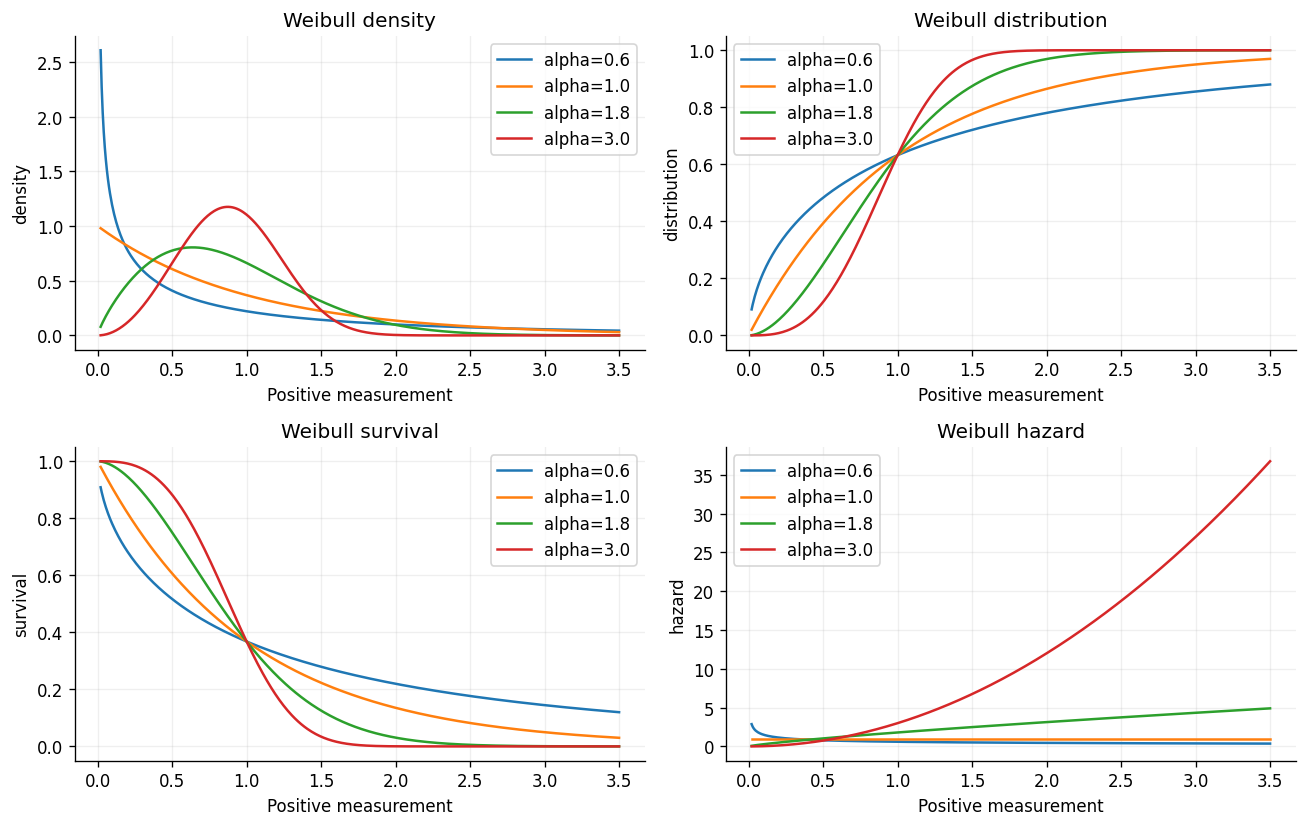

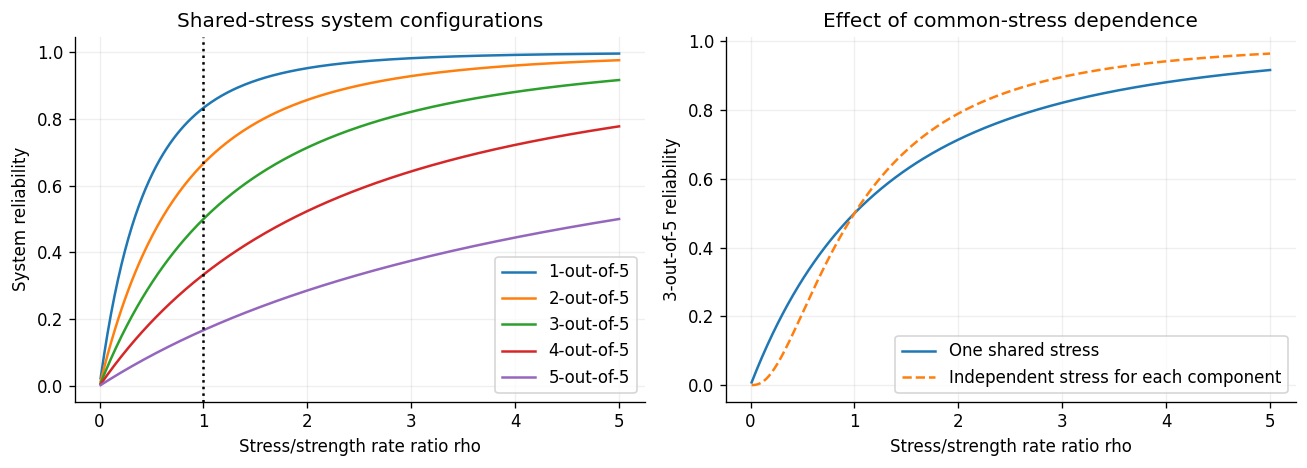

In [2]:
z=np.linspace(.02,3.5,500)
fig,axes=plt.subplots(2,2,figsize=(11,7))
for ash in [.6,1.,1.8,3.]:
    rate=1.
    axes[0,0].plot(z,ash*rate*z**(ash-1)*np.exp(-rate*z**ash),label=f'alpha={ash}')
    axes[0,1].plot(z,1-np.exp(-rate*z**ash),label=f'alpha={ash}')
    axes[1,0].plot(z,np.exp(-rate*z**ash),label=f'alpha={ash}')
    axes[1,1].plot(z,ash*rate*z**(ash-1),label=f'alpha={ash}')
for ax,title in zip(axes.flat,['Weibull density','Weibull distribution','Weibull survival','Weibull hazard']):
    ax.set(title=title,xlabel='Positive measurement',ylabel=title.split()[-1]);ax.legend()
fig.tight_layout();save_figure('01_weibull_functions')
rho=np.linspace(.01,5,300)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for s in [1,2,3,4,5]:
    axes[0].plot(rho,reliability(np.ones_like(rho),rho,s,5),label=f'{s}-out-of-5')
axes[0].axvline(1,color='black',linestyle=':');axes[0].set(xlabel='Stress/strength rate ratio rho',ylabel='System reliability',title='Shared-stress system configurations');axes[0].legend()
correct=reliability(np.ones_like(rho),rho)
independent=stats.binom.sf(2,5,rho/(1+rho))
axes[1].plot(rho,correct,label='One shared stress');axes[1].plot(rho,independent,label='Independent stress for each component',linestyle='--')
axes[1].set(xlabel='Stress/strength rate ratio rho',ylabel='3-out-of-5 reliability',title='Effect of common-stress dependence');axes[1].legend()
fig.tight_layout();save_figure('02_reliability')

## 11. Numerical verification
The theoretical reliability is checked against direct integration and independent simulation of complete systems. The record transformation, restricted optimization, information matrix and posterior integration are also checked independently.

In [3]:
rng=np.random.default_rng(SEED+1)
checks=[]
for ash,aa,bb in [(.8,.8,1.6),(1.8,1.,1.),(2.5,1.6,.8)]:
    exact=float(reliability(aa,bb))
    integral=integrate.quad(lambda t: stats.binom.sf(2,5,np.exp(-aa*t))*bb*np.exp(-bb*t),0,np.inf,epsabs=1e-11)[0]
    strengths=(rng.exponential(size=(200000,5))/aa)**(1/ash)
    stress=(rng.exponential(size=200000)/bb)**(1/ash)
    direct=np.mean((strengths>stress[:,None]).sum(axis=1)>=3)
    se=np.sqrt(exact*(1-exact)/len(stress))
    assert abs(exact-integral)<1e-9
    assert abs(direct-exact)<5*se
    checks.append(dict(check='Reliability',alpha=ash,a=aa,b=bb,formula=exact,integral=integral,system_MC=direct,MCSE=se))
verification_data=simulate_data((1.8,1.6,.8),rng=rng)
u=fit_mle(verification_data);o=fit_mle(verification_data,True)
independent_fit=optimize.minimize(lambda zz:-loglik(np.exp(zz),verification_data),np.log(u)+.1,method='BFGS',options={'gtol':1e-7})
assert np.max(np.abs(np.exp(independent_fit.x)-u))<1e-4
constraint={'type':'ineq','fun':lambda zz:zz[2]-zz[1]}
independent_ordered=optimize.minimize(lambda zz:-loglik(np.exp(zz),verification_data),np.log(o),method='SLSQP',constraints=[constraint],options={'ftol':1e-10,'maxiter':1000})
assert abs(loglik(np.exp(independent_ordered.x),verification_data)-loglik(o,verification_data))<1e-6
numerical_hessian=np.zeros((3,3));eps=1e-4
for i in range(3):
    for j in range(3):
        ei=np.eye(3)[i]*eps;ej=np.eye(3)[j]*eps
        numerical_hessian[i,j]=-(loglik(u+ei+ej,verification_data)-loglik(u+ei-ej,verification_data)-loglik(u-ei+ej,verification_data)+loglik(u-ei-ej,verification_data))/(4*eps**2)
hessian_error=np.max(np.abs(numerical_hessian-observed_information(u,verification_data)))
assert hessian_error<1e-3
hazard_end=rng.gamma(8,1,size=100000)
record_gamma_check=dict(empirical_mean=hazard_end.mean(),theoretical_mean=8.,empirical_variance=hazard_end.var(),theoretical_variance=8.)
record_paths=np.cumsum(rng.exponential(1/3,size=(100000,8)),axis=1)
assert abs((3*record_paths[:,-1]).mean()-8)<.04
reliability_checks=pd.DataFrame(checks)
reliability_checks.to_csv(ROOT/'results/reliability_verification.csv',index=False)
display(reliability_checks)
display(pd.DataFrame([dict(check='Observed information finite-difference error',value=hessian_error),dict(check='Ordered optimizer log-likelihood difference',value=abs(loglik(np.exp(independent_ordered.x),verification_data)-loglik(o,verification_data)))]))

,check,alpha,a,b,formula,integral,system_MC,MCSE
0,Reliability,0.8,0.8,1.6,0.714286,0.714286,0.713380,0.001010
1,Reliability,1.8,1.0,1.0,0.500000,0.500000,0.501965,0.001118
2,Reliability,2.5,1.6,0.8,0.307359,0.307359,0.308180,0.001032


,check,value
0,Observed information finite-difference error,0.000161
1,Ordered optimizer log-likelihood difference,0.000000


## 12. Monte Carlo study

The factorial design comprises 3 order regimes x 2 shapes x 2 block sizes x 2 hybrid protocols x 2 record orders = 48 scenarios. Each has 300 independent replications, for 14,400 independently simulated datasets. There are three blocks, $n=20$ or $n=40$ per block, $m=\lfloor0.7n\rfloor$, a balanced withdrawal plan, and T at the true strength distribution's 65th percentile. The threshold is fixed before generating each experiment. Shapes are 0.8 and 1.8; $k$ is 1 or 3; the prescribed record count is 6 for $n=20$ and 12 for $n=40$. This size contrast increases both strength and stress information; it does not isolate the effect of strength sample size alone.

Rate regimes are ordered $(a,b)=(0.8,1.6)$, boundary $(a,b)=(1,1)$, and violated $(a,b)=(1.6,0.8)$. Parameters are fixed, not sampled from priors. All four estimators use exactly the same simulated observations in a replication. Reported targets are $\alpha$, $a$, $b$ and $R_{3,5}$. Restricted estimators in the violated regime are intentionally misspecified and are judged against the true unrestricted target.

For estimates $\widehat\theta_l$ and truth $\theta$, let $e_l=\widehat\theta_l-\theta$. Report

$$\operatorname{Bias}=\frac1M\sum_{l=1}^{M}e_l,\qquad\operatorname{MSE}=\frac1M\sum_{l=1}^{M}e_l^2,$$

$$\operatorname{RMSE}=\sqrt{\operatorname{MSE}},\qquad\operatorname{MCSE}(\operatorname{Bias})=\frac{\operatorname{SD}(e_l)}{\sqrt{M}},$$

$$\operatorname{MCSE}(\operatorname{MSE})=\frac{\operatorname{SD}(e_l^2)}{\sqrt{M}}.$$

For intervals, report coverage $\widehat{\operatorname{CP}}$, average length and

$$\operatorname{MCSE}(\widehat{\operatorname{CP}})=\sqrt{\frac{\widehat{\operatorname{CP}}(1-\widehat{\operatorname{CP}})}{M}}.$$ The main coverage table includes unrestricted log-ratio asymptotic intervals and unrestricted/restricted Bayesian equal-tail intervals. Restricted MLE bootstrap coverage is separately measured in six selected scenarios with 100 outer replications and 199 inner resamples; its greater Monte Carlo uncertainty is displayed. The primary simulation's restricted MLE has no invented regular normal interval.

All raw replications, scenario settings, summary tables, numerical-refinement results and figures are exported. Seeds are fixed, and computational failures and specimen conservation are audited. Conclusions refer to the measured results rather than asserting universal Bayesian superiority.


In [4]:
design,simulation_raw,simulation=run_simulation(300)
display(design)
Rsummary=simulation[simulation.parameter=='R_3_5']
display(Rsummary[['scenario','regime','censoring','n_per_block','record_k','method','truth','bias','mse','bias_mcse','mse_mcse','coverage','coverage_mcse','average_length']])
refinement=[]
for row in design.itertuples():
    rr=np.random.default_rng(SEED+row.scenario*10000)
    dd=simulate_data((row.alpha,row.lambda_X,row.lambda_Y),n=row.n_per_block,k=row.record_k,r=row.record_count,mode=row.censoring,rng=rr)
    for ordered in [False,True]:
        coarse=posterior_grid(dd,ordered,na=80,np_=110)
        fine=posterior_grid(dd,ordered,na=200,np_=280)
        refinement.append(dict(scenario=row.scenario,restricted=ordered,max_mean_difference=np.max(np.abs(coarse['means']-fine['means'])),R_mean_difference=abs(coarse['means'][-1]-fine['means'][-1]),max_interval_endpoint_difference=np.max(np.abs(coarse['ci']-fine['ci'])),edge_mass=coarse['edge_mass']))
refinement=pd.DataFrame(refinement)
refinement.to_csv(ROOT/'results/quadrature_refinement.csv',index=False)
assert refinement.R_mean_difference.max()<.002
assert refinement.edge_mass.max()<1e-6
assert simulation_raw.grid_edge_mass.max()<1e-5
assert len(simulation_raw)==48*300*4
assert np.isfinite(simulation_raw[PARAMETERS].to_numpy()).all()
display(refinement.describe().loc[['mean','max']])

Completed 4/48 scenarios


Completed 8/48 scenarios


Completed 12/48 scenarios


Completed 16/48 scenarios


Completed 20/48 scenarios


...

Completed 44/48 scenarios


Completed 48/48 scenarios


,scenario,regime,alpha,lambda_X,lambda_Y,n_per_block,blocks,m_per_block,T_quantile,record_k,record_count,censoring,truth_R,repetitions
0,1,ordered,0.8,0.8,1.6,20,3,14,0.65,1,6,typeI,0.714286,300
1,2,ordered,0.8,0.8,1.6,20,3,14,0.65,3,6,typeI,0.714286,300
2,3,ordered,0.8,0.8,1.6,20,3,14,0.65,1,6,adaptiveII,0.714286,300
3,4,ordered,0.8,0.8,1.6,20,3,14,0.65,3,6,adaptiveII,0.714286,300
4,5,ordered,0.8,0.8,1.6,40,3,28,0.65,1,12,typeI,0.714286,300
5,6,ordered,0.8,0.8,1.6,40,3,28,0.65,3,12,typeI,0.714286,300
6,7,ordered,0.8,0.8,1.6,40,3,28,0.65,1,12,adaptiveII,0.714286,300
7,8,ordered,0.8,0.8,1.6,40,3,28,0.65,3,12,adaptiveII,0.714286,300
8,9,ordered,1.8,0.8,1.6,20,3,14,0.65,1,6,typeI,0.714286,300
9,10,ordered,1.8,0.8,1.6,20,3,14,0.65,3,6,typeI,0.714286,300


,scenario,regime,censoring,n_per_block,record_k,method,truth,bias,mse,bias_mcse,mse_mcse,coverage,coverage_mcse,average_length
3,1,ordered,typeI,20,1,MLE,0.714286,-0.002264,0.017670,0.007686,0.001513,0.950000,0.012583,0.479144
7,1,ordered,typeI,20,1,Restricted MLE,0.714286,0.003074,0.014700,0.007009,0.000922,NaN,NaN,NaN
11,1,ordered,typeI,20,1,Bayes,0.714286,-0.041761,0.012890,0.006105,0.001200,0.970000,0.009849,0.476046
15,1,ordered,typeI,20,1,Restricted Bayes,0.714286,-0.002219,0.004665,0.003948,0.000341,0.996667,0.003328,0.357798
19,2,ordered,typeI,20,3,MLE,0.714286,0.007206,0.013654,0.006745,0.001114,0.956667,0.011755,0.441317
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
751,47,violated,adaptiveII,40,1,Restricted Bayes,0.307359,0.237700,0.056736,0.000886,0.000445,0.000000,0.000000,0.141800
755,48,violated,adaptiveII,40,3,MLE,0.307359,0.000709,0.006628,0.004708,0.000546,0.950000,0.012583,0.306724
759,48,violated,adaptiveII,40,3,Restricted MLE,0.307359,0.193287,0.037391,0.000323,0.000142,NaN,NaN,NaN
763,48,violated,adaptiveII,40,3,Bayes,0.307359,0.019584,0.005949,0.004314,0.000518,0.956667,0.011755,0.298539


,scenario,max_mean_difference,R_mean_difference,max_interval_endpoint_difference,edge_mass
mean,24.5,0.000880,0.000123,0.000582,9.676995e-41
max,48.0,0.010088,0.001373,0.001728,4.711767e-39


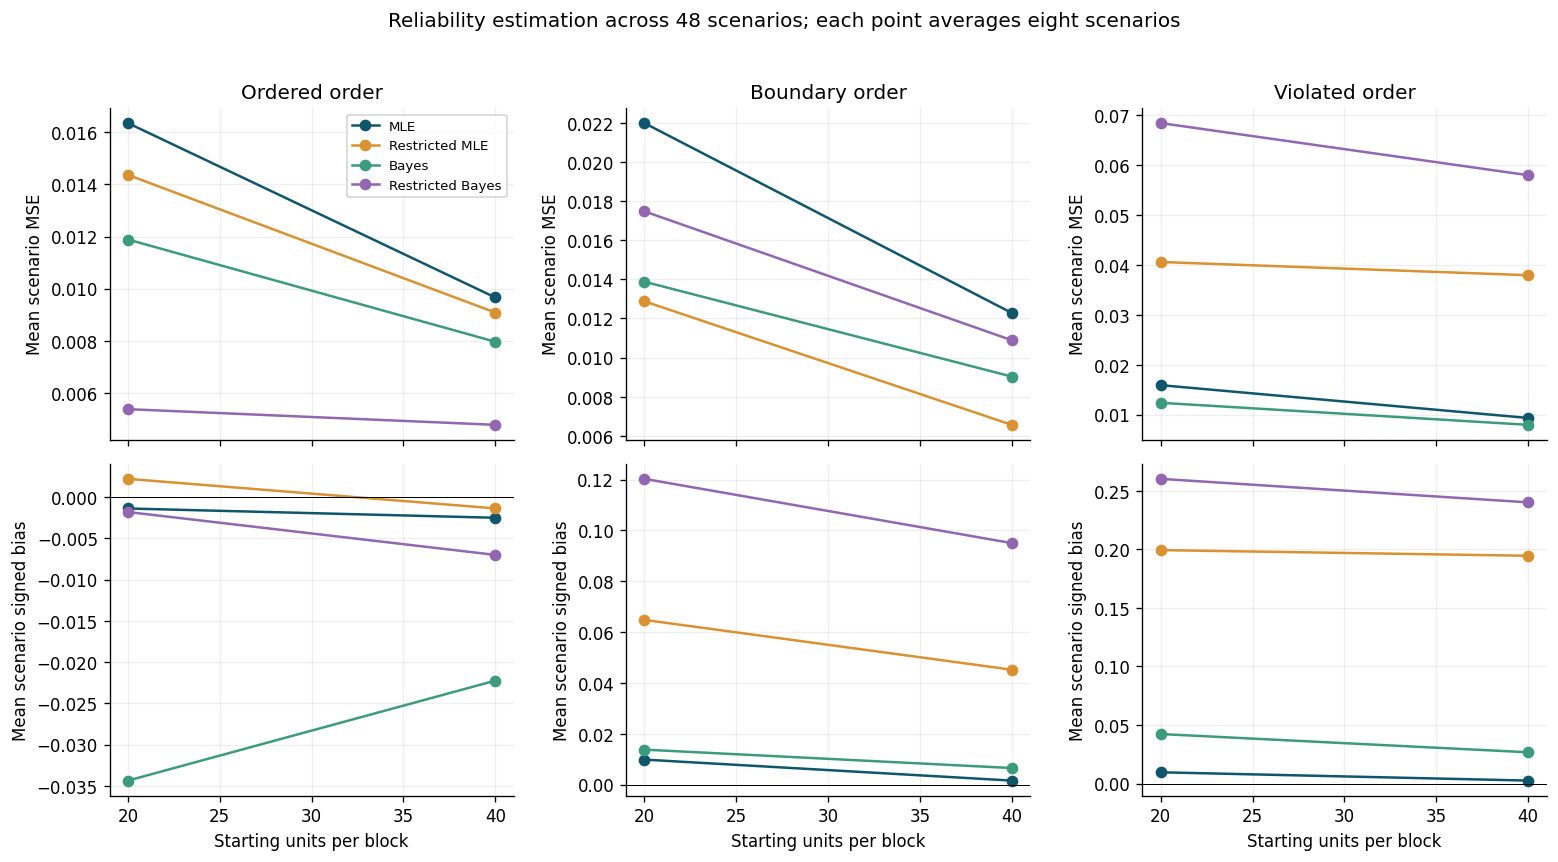

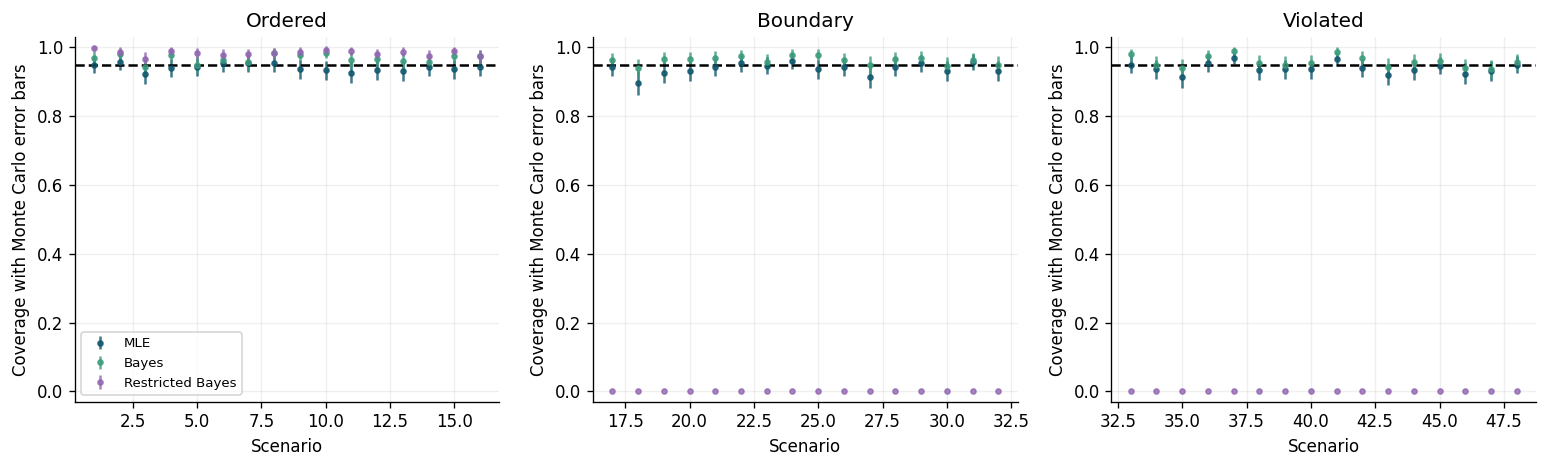

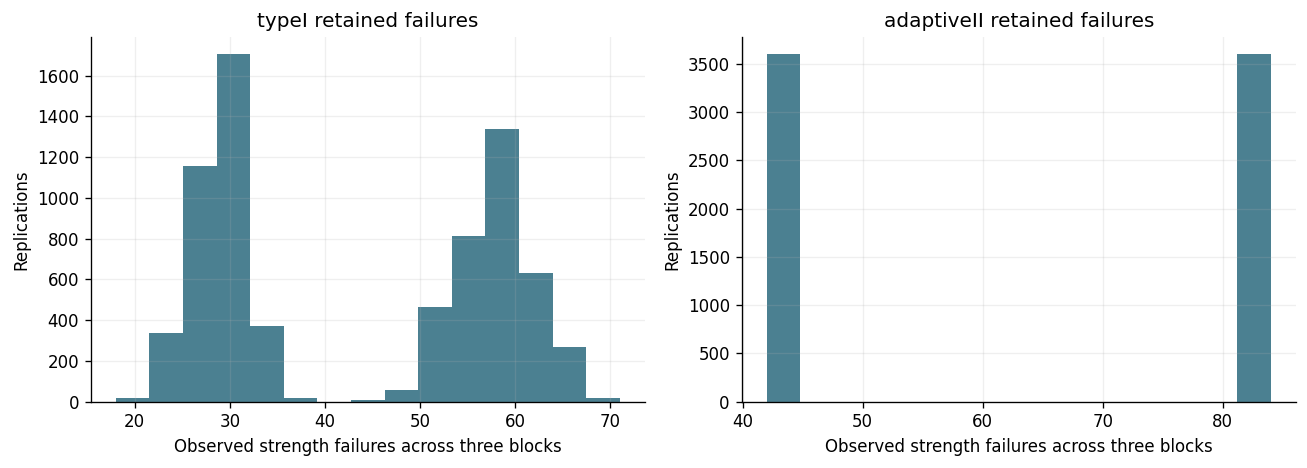

In [5]:
colors={'MLE':'#0f566c','Restricted MLE':'#da9132','Bayes':'#3c9b7d','Restricted Bayes':'#9266b0'}
fig,axes=plt.subplots(2,3,figsize=(13,7),sharex=True)
for column,regime in enumerate(['ordered','boundary','violated']):
    sub=Rsummary[Rsummary.regime==regime]
    for method in colors:
        ss=sub[sub.method==method].groupby('n_per_block')[['mse','bias']].mean()
        axes[0,column].plot(ss.index,ss.mse,'o-',label=method,color=colors[method])
        axes[1,column].plot(ss.index,ss.bias,'o-',label=method,color=colors[method])
    axes[0,column].set(title=regime.capitalize()+' order',ylabel='Mean scenario MSE')
    axes[1,column].set(xlabel='Starting units per block',ylabel='Mean scenario signed bias');axes[1,column].axhline(0,color='black',linewidth=.6)
axes[0,0].legend(fontsize=8)
fig.suptitle('Reliability estimation across 48 scenarios; each point averages eight scenarios',y=1.02)
fig.tight_layout();save_figure('03_simulation_bias_mse')
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,regime in zip(axes,['ordered','boundary','violated']):
    sub=Rsummary[Rsummary.regime==regime]
    for method in ['MLE','Bayes','Restricted Bayes']:
        ss=sub[sub.method==method]
        ax.errorbar(ss.scenario,ss.coverage,yerr=1.96*ss.coverage_mcse,fmt='o',ms=3,label=method,color=colors[method],alpha=.8)
    ax.axhline(.95,color='black',linestyle='--');ax.set(title=regime.capitalize(),xlabel='Scenario',ylabel='Coverage with Monte Carlo error bars',ylim=(-.03,1.03))
axes[0].legend(fontsize=8);fig.tight_layout();save_figure('04_simulation_coverage')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,mode in zip(axes,['typeI','adaptiveII']):
    sub=simulation_raw.merge(design[['scenario','censoring','n_per_block']],on='scenario')
    sub=sub[(sub.method=='MLE')&(sub.censoring==mode)]
    ax.hist(sub.observed_failures,bins=15,alpha=.75,color='#0f566c');ax.set(title=mode+' retained failures',xlabel='Observed strength failures across three blocks',ylabel='Replications')
fig.tight_layout();save_figure('05_observed_information')

In [6]:
selected=design[(design.alpha==1.8)&(design.n_per_block==20)&(design.record_k==3)]
boot_rows=[]
for row in selected.itertuples():
    rr=np.random.default_rng(SEED+500000+row.scenario)
    covered=[];length=[];failed=0
    for outer in range(100):
        dd=simulate_data((row.alpha,row.lambda_X,row.lambda_Y),n=20,k=3,r=6,mode=row.censoring,rng=rr)
        estimate=fit_mle(dd,True)
        draws,nfailed=bootstrap_reliability(estimate,dd,rr,B=199,restricted=True)
        ci=np.quantile(draws,[.025,.975])
        covered.append(ci[0]-1e-10<=row.truth_R<=ci[1]+1e-10)
        length.append(ci[1]-ci[0]);failed+=nfailed
    cp=np.mean(covered)
    boot_rows.append(dict(scenario=row.scenario,regime=row.regime,censoring=row.censoring,outer_replications=100,inner_resamples=199,coverage=cp,coverage_mcse=np.sqrt(cp*(1-cp)/100),average_length=np.mean(length),failed_inner_fits=failed))
    print(f'Restricted bootstrap coverage: scenario {row.scenario} complete',flush=True)
bootstrap_coverage=pd.DataFrame(boot_rows)
bootstrap_coverage.to_csv(ROOT/'results/restricted_bootstrap_coverage.csv',index=False)
display(bootstrap_coverage)

Restricted bootstrap coverage: scenario 10 complete


Restricted bootstrap coverage: scenario 12 complete


Restricted bootstrap coverage: scenario 26 complete


Restricted bootstrap coverage: scenario 28 complete


Restricted bootstrap coverage: scenario 42 complete


Restricted bootstrap coverage: scenario 44 complete


,scenario,regime,censoring,outer_replications,inner_resamples,coverage,coverage_mcse,average_length,failed_inner_fits
0,10,ordered,typeI,100,199,0.91,0.028618,0.370554,0
1,12,ordered,adaptiveII,100,199,0.86,0.034699,0.363888,0
2,26,boundary,typeI,100,199,0.94,0.023749,0.340262,0
3,28,boundary,adaptiveII,100,199,0.91,0.028618,0.343433,0
4,42,violated,typeI,100,199,0.00,0.000000,0.320950,0
5,44,violated,adaptiveII,100,199,0.00,0.000000,0.305552,0


## 13. Published-data validation

The source is Table 10, printed page 3453 (PDF page 19), of Sultana et al. (2026), attributing jute-fibre breaking-strength data to Xia et al. (2009). The provided values have already been divided by 1000. We transcribe all 30 observations at each of the 15 mm and 20 mm gauge lengths in table order. We do not silently repair the printed 70.32383 in the 10 mm group; that group is excluded because its anomalous value needs verification against the original experiment.

The 15 mm population is the strength population and the 20 mm population is the comparison stress population. This is a same-unit laboratory stress-strength comparison of breaking-strength populations. The latter observations are not measured external operating loads, so the reliability is not a certified in-service engineering probability. The order assumption is assessed as a sensitivity case.

Complete data are first checked using separate Weibull fits, histograms and densities, empirical versus fitted CDFs, Q-Q plots, and bootstrap-calibrated K-S goodness-of-fit tests with 1,000 resamples and refitting in every resample. A common-shape likelihood-ratio test uses one degree of freedom for two populations and a 1,000-replicate parametric bootstrap calibration. Failure to reject is model compatibility, not proof of the Weibull model or equal shapes.

A reproducible retrospective design then splits the 15 mm observations randomly into three disjoint blocks of ten, with target seven failures, balanced withdrawals, and $T=0.5$ in the scaled measurement unit. The principal application uses Type-I progressive hybrid censoring; the adaptive Type-II version is also fitted. From the 20 mm values in printed table order we retain the first six upper $k=2$ records, stopping at original position nine. Remaining stress observations are used only in the complete-data fit check. All full and retained datasets and realized withdrawals are saved. The table order is an imposed acquisition order; a random-order sensitivity study quantifies its effect.

The application reports unrestricted/restricted likelihood and posterior estimates, parameter intervals, reliability intervals, 500-replicate parametric bootstraps, prior sensitivity, hybrid-protocol sensitivity, record-count/order sensitivity, posterior diagnostics, and posterior predictive checks. A finite-record sequence contains much less information than the complete stress sample; its uncertainty should be retained in the interpretation.



,sample,n,alpha,rate,KS,bootstrap_p,bootstrap_B,AIC
0,15 mm,30,1.499123,3.908007,0.168763,0.025974,1000,-2.806160
1,20 mm,30,1.360689,3.839206,0.149038,0.077922,1000,-4.364594


,LR,df,asymptotic_p,bootstrap_p,common_shape,lambda_X,lambda_Y,B
0,0.208262,1,0.648133,0.62038,1.425471,3.724783,4.012422,1000


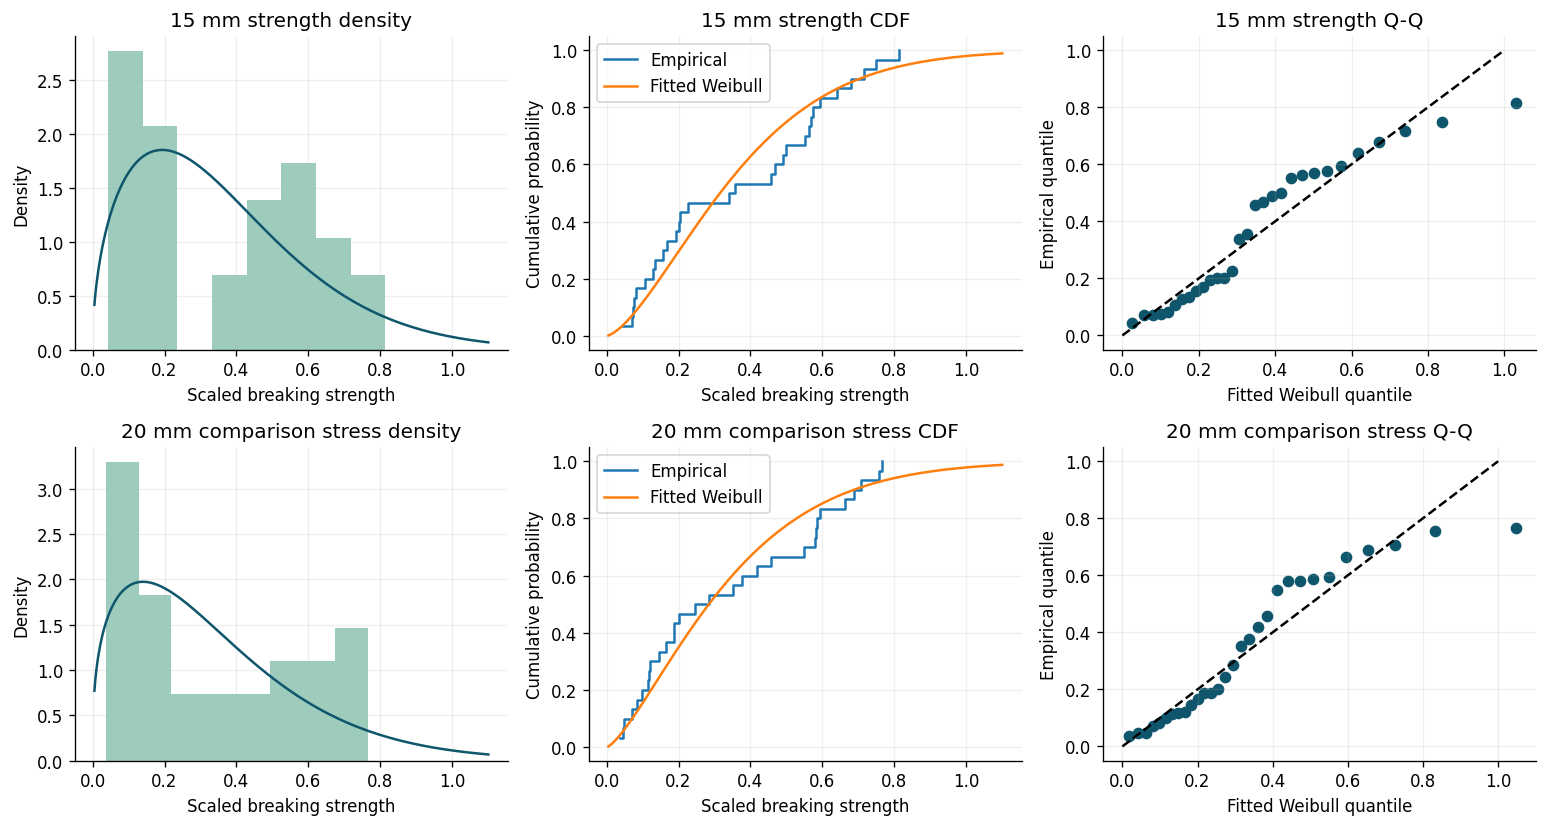

In [7]:
measurements=pd.read_csv(ROOT/'data/jute_fibre.csv')
x=measurements.gauge_15mm.to_numpy();y=measurements.gauge_20mm.to_numpy()
assert len(x)==len(y)==30 and np.all(x>0) and np.all(y>0)
gof,shape_test=goodness_of_fit(x,y,np.random.default_rng(SEED+20),B=1000)
gof.to_csv(ROOT/'results/goodness_of_fit.csv',index=False)
(ROOT/'results/common_shape_test.json').write_text(json.dumps(shape_test,indent=2))
display(gof);display(pd.DataFrame([shape_test]))
fig,axes=plt.subplots(2,3,figsize=(13,7))
for row,(label,sample) in enumerate([('15 mm strength',x),('20 mm comparison stress',y)]):
    ash,rate,ll=iid_fit(sample);zz=np.linspace(.005,1.1,400);zsort=np.sort(sample);prob=(np.arange(1,31)-.5)/30
    axes[row,0].hist(sample,bins=8,density=True,alpha=.5,color='#3c9b7d');axes[row,0].plot(zz,ash*rate*zz**(ash-1)*np.exp(-rate*zz**ash),color='#0f566c');axes[row,0].set(title=label+' density',xlabel='Scaled breaking strength',ylabel='Density')
    axes[row,1].step(zsort,np.arange(1,31)/30,where='post',label='Empirical');axes[row,1].plot(zz,1-np.exp(-rate*zz**ash),label='Fitted Weibull');axes[row,1].set(title=label+' CDF',xlabel='Scaled breaking strength',ylabel='Cumulative probability');axes[row,1].legend()
    theoretical=(-np.log1p(-prob)/rate)**(1/ash)
    axes[row,2].scatter(theoretical,zsort,color='#0f566c');axes[row,2].plot([0,1],[0,1],linestyle='--',color='black');axes[row,2].set(title=label+' Q-Q',xlabel='Fitted Weibull quantile',ylabel='Empirical quantile')
fig.tight_layout();save_figure('06_real_data_fit')

,block,failure_number,failure,withdrawn_at_failure,terminal_time,terminal_survivors
0,1,1,0.07638,1,0.5,4
1,1,2,0.20275,1,0.5,4
2,1,3,0.33922,1,0.5,4
3,2,1,0.07224,1,0.5,2
4,2,2,0.10673,1,0.5,2
5,2,3,0.20076,1,0.5,2
6,2,4,0.22565,0,0.5,2
7,2,5,0.46847,0,0.5,2
8,3,1,0.04266,1,0.5,2
9,3,2,0.07009,1,0.5,2


,record_number,k,value,source_position
0,1,2,0.07146,2
1,2,2,0.28464,3
2,3,2,0.41902,4
3,4,2,0.45660,5
4,5,2,0.58557,8
5,6,2,0.66266,9


,method,alpha,lambda_X,lambda_Y,R_3_5,lower,upper,interval_type
0,MLE,1.165619,2.116695,4.846499,0.752605,0.444462,0.944557,Log-ratio asymptotic CI
1,Restricted MLE,1.165619,2.116695,4.846499,0.752605,0.500000,0.946881,Parametric bootstrap percentile CI
2,Bayes,1.178832,2.201313,3.901072,0.665593,0.380472,0.894740,Posterior equal-tail credible interval
3,Restricted Bayes,1.165385,2.103929,4.127149,0.698883,0.515746,0.898782,Posterior equal-tail credible interval


,method,parameter,estimate,lower,upper,interval_type
0,Bayes,alpha,1.178832,0.793319,1.615915,Posterior equal-tail
1,Restricted Bayes,alpha,1.165385,0.793319,1.615915,Posterior equal-tail
2,MLE,alpha,1.165619,0.790146,1.719514,Positive log-normal asymptotic CI
3,Bayes,lambda_X,2.201313,1.066163,3.941935,Posterior equal-tail
4,Restricted Bayes,lambda_X,2.103929,1.034747,3.659575,Posterior equal-tail
5,MLE,lambda_X,2.116695,1.022314,4.382605,Positive log-normal asymptotic CI
6,Bayes,lambda_Y,3.901072,1.566057,7.269701,Posterior equal-tail
7,Restricted Bayes,lambda_Y,4.127149,1.975649,7.425670,Posterior equal-tail
8,MLE,lambda_Y,4.846499,2.131150,11.021539,Positive log-normal asymptotic CI


,model,LINEX_positive,LINEX_negative,shortest_lower,shortest_upper,bootstrap_lower,bootstrap_upper,failed_bootstrap_fits
0,Unrestricted,0.651642,0.678863,0.409236,0.913144,0.424441,0.946855,0
1,Restricted,0.690612,0.707247,0.502044,0.875375,0.500000,0.946881,0


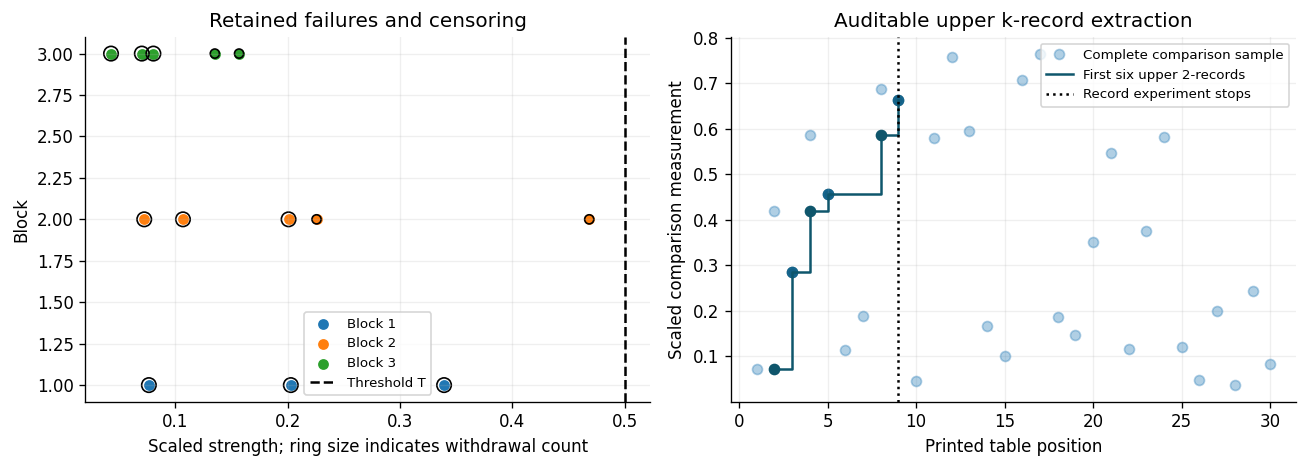

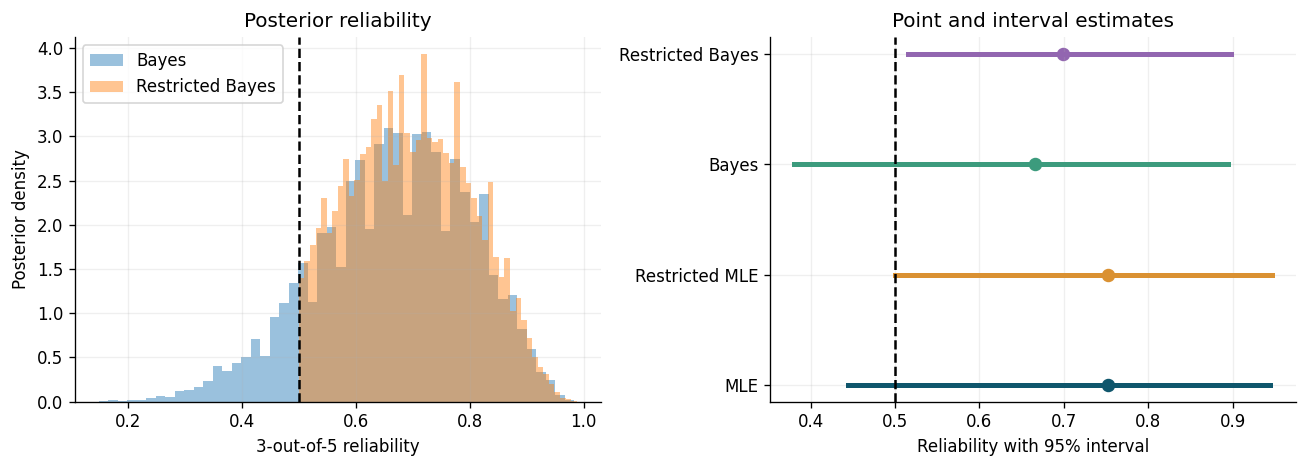

In [8]:
rng=np.random.default_rng(SEED)
partition=np.array_split(rng.permutation(np.arange(30)),3)
blocks=[];block_rows=[]
for i,indices in enumerate(partition,1):
    block=censor_block(x[indices],7,.5,removal_plan(10,7),rng,'typeI');blocks.append(block)
    for j,(failure,removed) in enumerate(zip(block['x'],block['R']),1):
        block_rows.append(dict(block=i,failure_number=j,failure=failure,withdrawn_at_failure=removed,terminal_time=block['terminal'],terminal_survivors=block['terminal_count']))
    if len(block['x'])==0:
        block_rows.append(dict(block=i,failure_number=0,failure=np.nan,withdrawn_at_failure=0,terminal_time=block['terminal'],terminal_survivors=block['terminal_count']))
block_table=pd.DataFrame(block_rows)
block_table.to_csv(ROOT/'data/real_censored_strength.csv',index=False)
pd.DataFrame({'block':np.repeat([1,2,3],10),'source_position':np.concatenate(partition)+1,'measurement':x[np.concatenate(partition)]}).to_csv(ROOT/'data/real_block_allocation.csv',index=False)
records,positions=extract_records(y,2,6)
record_table=pd.DataFrame({'record_number':np.arange(1,7),'k':2,'value':records,'source_position':positions})
record_table.to_csv(ROOT/'data/real_upper_k_records.csv',index=False)
real_data=make_data(blocks,records,2)
u=fit_mle(real_data);o=fit_mle(real_data,True)
gu=posterior_grid(real_data,na=240,np_=320);go=posterior_grid(real_data,True,na=240,np_=320)
parameter_aci,Raci=asymptotic_intervals(u,real_data)
posterior_u=posterior_draws(gu,np.random.default_rng(SEED+50),40000)
posterior_o=posterior_draws(go,np.random.default_rng(SEED+51),40000)
boot_u,fail_u=bootstrap_reliability(u,real_data,np.random.default_rng(SEED+52),B=500)
boot_o,fail_o=bootstrap_reliability(o,real_data,np.random.default_rng(SEED+53),B=500,restricted=True)
intervals={'MLE':Raci,'Restricted MLE':np.quantile(boot_o,[.025,.975]),'Bayes':gu['ci'],'Restricted Bayes':go['ci']}
fits={'MLE':np.r_[u,reliability(*u[1:])],'Restricted MLE':np.r_[o,reliability(*o[1:])],'Bayes':gu['means'],'Restricted Bayes':go['means']}
real_rows=[]
for method,est in fits.items():
    real_rows.append(dict(method=method,alpha=est[0],lambda_X=est[1],lambda_Y=est[2],R_3_5=est[3],lower=intervals[method][0],upper=intervals[method][1],interval_type='Log-ratio asymptotic CI' if method=='MLE' else 'Parametric bootstrap percentile CI' if method=='Restricted MLE' else 'Posterior equal-tail credible interval'))
real_estimates=pd.DataFrame(real_rows)
real_estimates.to_csv(ROOT/'results/real_estimates.csv',index=False)
pd.DataFrame({'unrestricted_bootstrap_R':boot_u,'restricted_bootstrap_R':boot_o}).to_csv(ROOT/'results/real_bootstrap.csv',index=False)
param_rows=[]
for j,name in enumerate(PARAMETERS[:3]):
    for label,draws in [('Bayes',posterior_u),('Restricted Bayes',posterior_o)]:
        ci=np.quantile(draws[:,j],[.025,.975]);param_rows.append(dict(method=label,parameter=name,estimate=fits[label][j],lower=ci[0],upper=ci[1],interval_type='Posterior equal-tail'))
    param_rows.append(dict(method='MLE',parameter=name,estimate=u[j],lower=parameter_aci[j,0],upper=parameter_aci[j,1],interval_type='Positive log-normal asymptotic CI'))
parameter_estimates=pd.DataFrame(param_rows)
parameter_estimates.to_csv(ROOT/'results/real_parameter_intervals.csv',index=False)
display(block_table);display(record_table);display(real_estimates);display(parameter_estimates)
display(pd.DataFrame([dict(model='Unrestricted',LINEX_positive=gu['linex'][1.5],LINEX_negative=gu['linex'][-1.5],shortest_lower=gu['hpd'][0],shortest_upper=gu['hpd'][1],bootstrap_lower=np.quantile(boot_u,.025),bootstrap_upper=np.quantile(boot_u,.975),failed_bootstrap_fits=fail_u),dict(model='Restricted',LINEX_positive=go['linex'][1.5],LINEX_negative=go['linex'][-1.5],shortest_lower=go['hpd'][0],shortest_upper=go['hpd'][1],bootstrap_lower=np.quantile(boot_o,.025),bootstrap_upper=np.quantile(boot_o,.975),failed_bootstrap_fits=fail_o)]))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for i,block in enumerate(blocks,1):
    axes[0].scatter(block['x'],np.full(len(block['x']),i),s=30,label=f'Block {i}')
    axes[0].scatter(block['x'],np.full(len(block['x']),i),s=30+45*block['R'],facecolors='none',edgecolors='black')
axes[0].axvline(.5,color='black',linestyle='--',label='Threshold T');axes[0].set(xlabel='Scaled strength; ring size indicates withdrawal count',ylabel='Block',title='Retained failures and censoring');axes[0].legend(fontsize=8)
axes[1].plot(np.arange(1,len(y)+1),y,'o',alpha=.35,label='Complete comparison sample');axes[1].step(positions,records,where='post',color='#0f566c',label='First six upper 2-records');axes[1].scatter(positions,records,color='#0f566c');axes[1].axvline(positions[-1],linestyle=':',color='black',label='Record experiment stops');axes[1].set(xlabel='Printed table position',ylabel='Scaled comparison measurement',title='Auditable upper k-record extraction');axes[1].legend(fontsize=8)
fig.tight_layout();save_figure('07_real_sampling')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for label,draws in [('Bayes',posterior_u),('Restricted Bayes',posterior_o)]:
    axes[0].hist(draws[:,-1],bins=50,density=True,alpha=.45,label=label)
axes[0].axvline(.5,linestyle='--',color='black');axes[0].set(xlabel='3-out-of-5 reliability',ylabel='Posterior density',title='Posterior reliability');axes[0].legend()
for j,row in enumerate(real_estimates.itertuples()):
    axes[1].plot([row.lower,row.upper],[j,j],color=colors[row.method],linewidth=3);axes[1].scatter(row.R_3_5,j,color=colors[row.method],s=50)
axes[1].set(yticks=np.arange(4),yticklabels=real_estimates.method,xlabel='Reliability with 95% interval',title='Point and interval estimates');axes[1].axvline(.5,linestyle='--',color='black')
fig.tight_layout();save_figure('08_real_reliability_intervals')

## 13.1. Additional validation on published carbon-fibre strengths
The calibrated jute checks reveal limited Weibull adequacy in one group. A second common-unit dataset provides an independent compatibility check. The 100 carbon-fibre strengths in GPa are transcribed from the supplied Journal of Mathematics article, section 5.1.1, pages 12 and 14, attributed there to Nichols and Padgett. A seeded random split produces disjoint strength and comparison groups of 50 each. Both remain laboratory breaking-strength populations. The analysis unit is 3 GPa, so measurements are divided by three before inference and the same fixed primary prior is used. No flood-discharge observations are mixed with these data. The first five upper 4-records contain no tied retained values; no jitter is applied to rounded measurements.

,sample,n,alpha,rate,KS,bootstrap_p,bootstrap_B,AIC
0,Carbon strength half,50,2.718622,1.180106,0.077618,0.585415,1000,33.725690
1,Carbon comparison half,50,2.897319,0.942051,0.113160,0.100899,1000,36.433131


,LR,df,asymptotic_p,bootstrap_p,common_shape,lambda_X,lambda_Y,B
0,0.172609,1,0.677804,0.678322,2.806143,1.16958,0.956592,1000


,method,alpha,lambda_X,lambda_Y,R_3_5,lower,upper
0,MLE,2.874157,1.340551,0.694858,0.316046,0.132734,0.614614
1,Restricted MLE,2.660469,1.135103,1.135103,0.500000,0.500000,0.862349
2,Bayes,2.783611,1.316923,0.826946,0.362275,0.158759,0.608057
3,Restricted Bayes,2.552330,1.080241,1.338216,0.565259,0.502032,0.703883


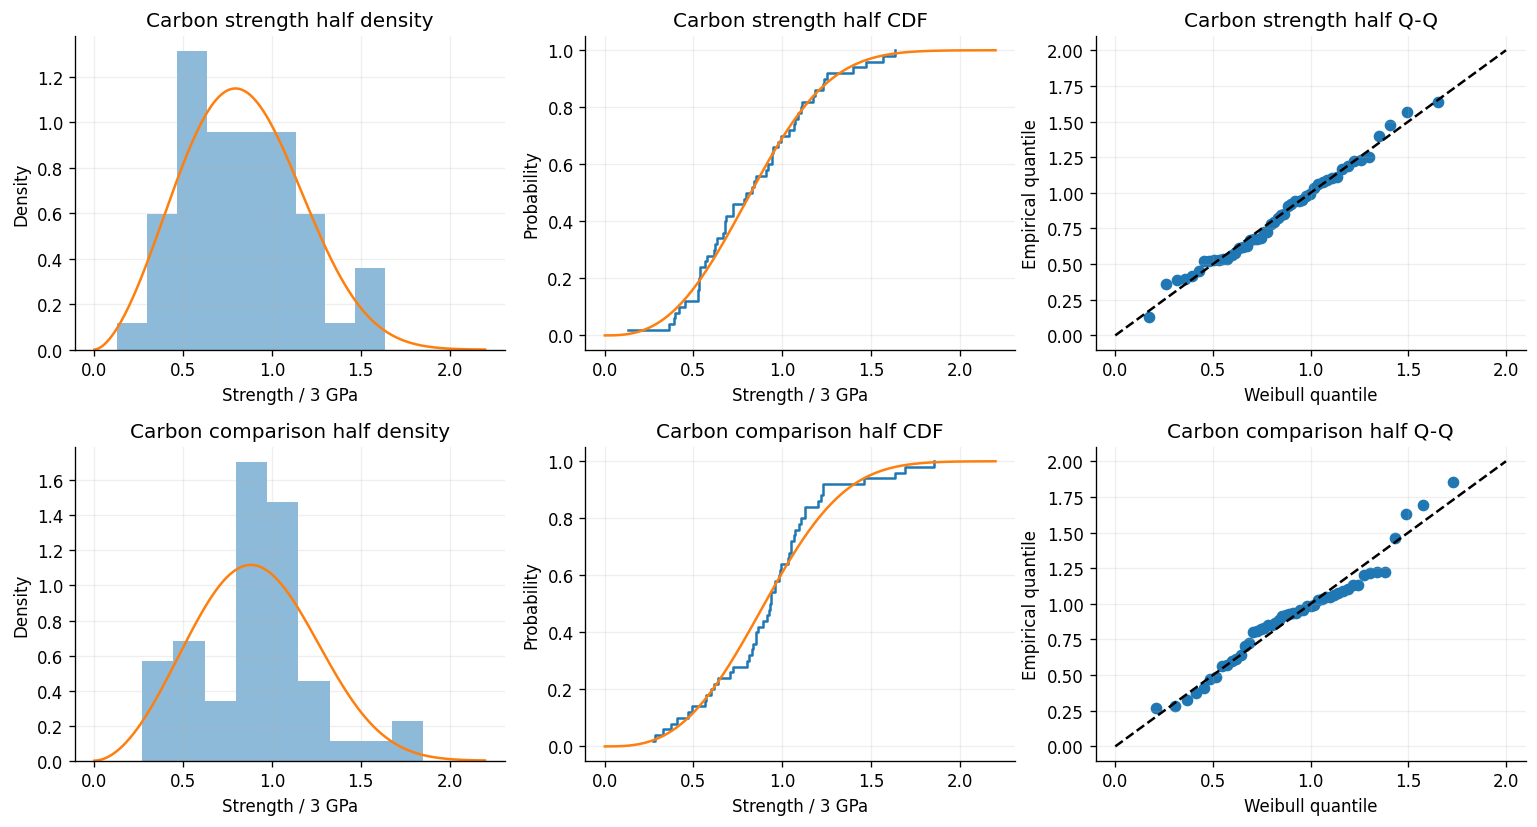

In [9]:
carbon=pd.read_csv(ROOT/'data/carbon_fibre.csv')
assert len(carbon)==100
crng=np.random.default_rng(SEED+70)
ci=crng.permutation(100)
cx=carbon.carbon_strength_GPa.to_numpy()[ci[:50]]/3
cy=carbon.carbon_strength_GPa.to_numpy()[ci[50:]]/3
carbon_gof,carbon_shape=goodness_of_fit(cx,cy,np.random.default_rng(SEED+71),B=1000)
carbon_gof['sample']=['Carbon strength half','Carbon comparison half']
carbon_gof.to_csv(ROOT/'results/carbon_goodness_of_fit.csv',index=False)
(ROOT/'results/carbon_common_shape_test.json').write_text(json.dumps(carbon_shape,indent=2))
cblocks=[];carbon_alloc=[]
for number,part in enumerate(np.array_split(np.arange(50),3),1):
    n=len(part);m=int(.7*n)
    cblocks.append(censor_block(cx[part],m,1.,removal_plan(n,m),crng))
    for local in part:
        carbon_alloc.append(dict(role='Strength',block=number,source_position=ci[local]+1,scaled_measurement=cx[local]))
for local in range(50):
    carbon_alloc.append(dict(role='Comparison stress',block=0,source_position=ci[50+local]+1,scaled_measurement=cy[local]))
pd.DataFrame(carbon_alloc).to_csv(ROOT/'data/carbon_allocation.csv',index=False)
crecords,cpositions=extract_records(cy,4,5)
pd.DataFrame({'record_number':range(1,6),'k':4,'scaled_value':crecords,'source_position':ci[50+cpositions-1]+1,'acquisition_position':cpositions}).to_csv(ROOT/'data/carbon_records.csv',index=False)
carbon_data=make_data(cblocks,crecords,4)
cu=fit_mle(carbon_data);co=fit_mle(carbon_data,True)
cgu=posterior_grid(carbon_data,na=240,np_=320);cgo=posterior_grid(carbon_data,True,na=240,np_=320)
_,caci=asymptotic_intervals(cu,carbon_data)
cboot,cfailed=bootstrap_reliability(co,carbon_data,np.random.default_rng(SEED+72),B=500,restricted=True)
carbon_rows=[]
for label,estimate,interval in [('MLE',np.r_[cu,reliability(*cu[1:])],caci),('Restricted MLE',np.r_[co,reliability(*co[1:])],np.quantile(cboot,[.025,.975])),('Bayes',cgu['means'],cgu['ci']),('Restricted Bayes',cgo['means'],cgo['ci'])]:
    carbon_rows.append(dict(method=label,alpha=estimate[0],lambda_X=estimate[1],lambda_Y=estimate[2],R_3_5=estimate[3],lower=interval[0],upper=interval[1]))
carbon_estimates=pd.DataFrame(carbon_rows)
carbon_estimates.to_csv(ROOT/'results/carbon_estimates.csv',index=False)
display(carbon_gof);display(pd.DataFrame([carbon_shape]));display(carbon_estimates)
fig,axes=plt.subplots(2,3,figsize=(13,7))
for row,(label,sample) in enumerate([('Carbon strength half',cx),('Carbon comparison half',cy)]):
    ash,rate,ll=iid_fit(sample);zz=np.linspace(.001,2.2,400);ss=np.sort(sample);prob=(np.arange(1,len(sample)+1)-.5)/len(sample)
    axes[row,0].hist(sample,bins=9,density=True,alpha=.5);axes[row,0].plot(zz,ash*rate*zz**(ash-1)*np.exp(-rate*zz**ash));axes[row,0].set(title=label+' density',xlabel='Strength / 3 GPa',ylabel='Density')
    axes[row,1].step(ss,np.arange(1,len(sample)+1)/len(sample),where='post');axes[row,1].plot(zz,1-np.exp(-rate*zz**ash));axes[row,1].set(title=label+' CDF',xlabel='Strength / 3 GPa',ylabel='Probability')
    tt=(-np.log1p(-prob)/rate)**(1/ash);axes[row,2].scatter(tt,ss);axes[row,2].plot([0,2],[0,2],'--',color='black');axes[row,2].set(title=label+' Q-Q',xlabel='Weibull quantile',ylabel='Empirical quantile')
fig.tight_layout();save_figure('12_carbon_data_fit')

## 14. Independent posterior sampler and convergence diagnostics
The quadrature computation is checked against Metropolis-Hastings in the collapsed transformed coordinates. The trace plots below show actual retained samples after warm-up; the conditional total-rate draw uses its exact Gamma distribution.

,parameter,split_Rhat,ESS,mean,MCSE,model,quadrature_mean,difference
0,alpha,1.000646,5645.480646,1.172200,0.002883,Unrestricted,1.178832,-0.006632
1,lambda_X,1.000211,9428.158942,2.189299,0.007639,Unrestricted,2.201313,-0.012014
2,lambda_Y,1.000901,8607.471754,3.870889,0.015909,Unrestricted,3.901072,-0.030183
3,R_3_5,1.000548,5996.147708,0.665015,0.001728,Unrestricted,0.665593,-0.000578
4,alpha,1.000131,6700.483360,1.163467,0.002574,Restricted,1.165385,-0.001918
5,lambda_X,1.000093,10088.202449,2.096724,0.006713,Restricted,2.103929,-0.007205
6,lambda_Y,1.000219,7673.139611,4.129281,0.016166,Restricted,4.127149,0.002132
7,R_3_5,1.000706,3976.890501,0.700257,0.001655,Restricted,0.698883,0.001374


,chain,unrestricted_acceptance,restricted_acceptance
0,1,0.408636,0.430091
1,2,0.412545,0.420909
2,3,0.410182,0.433455
3,4,0.412273,0.421818


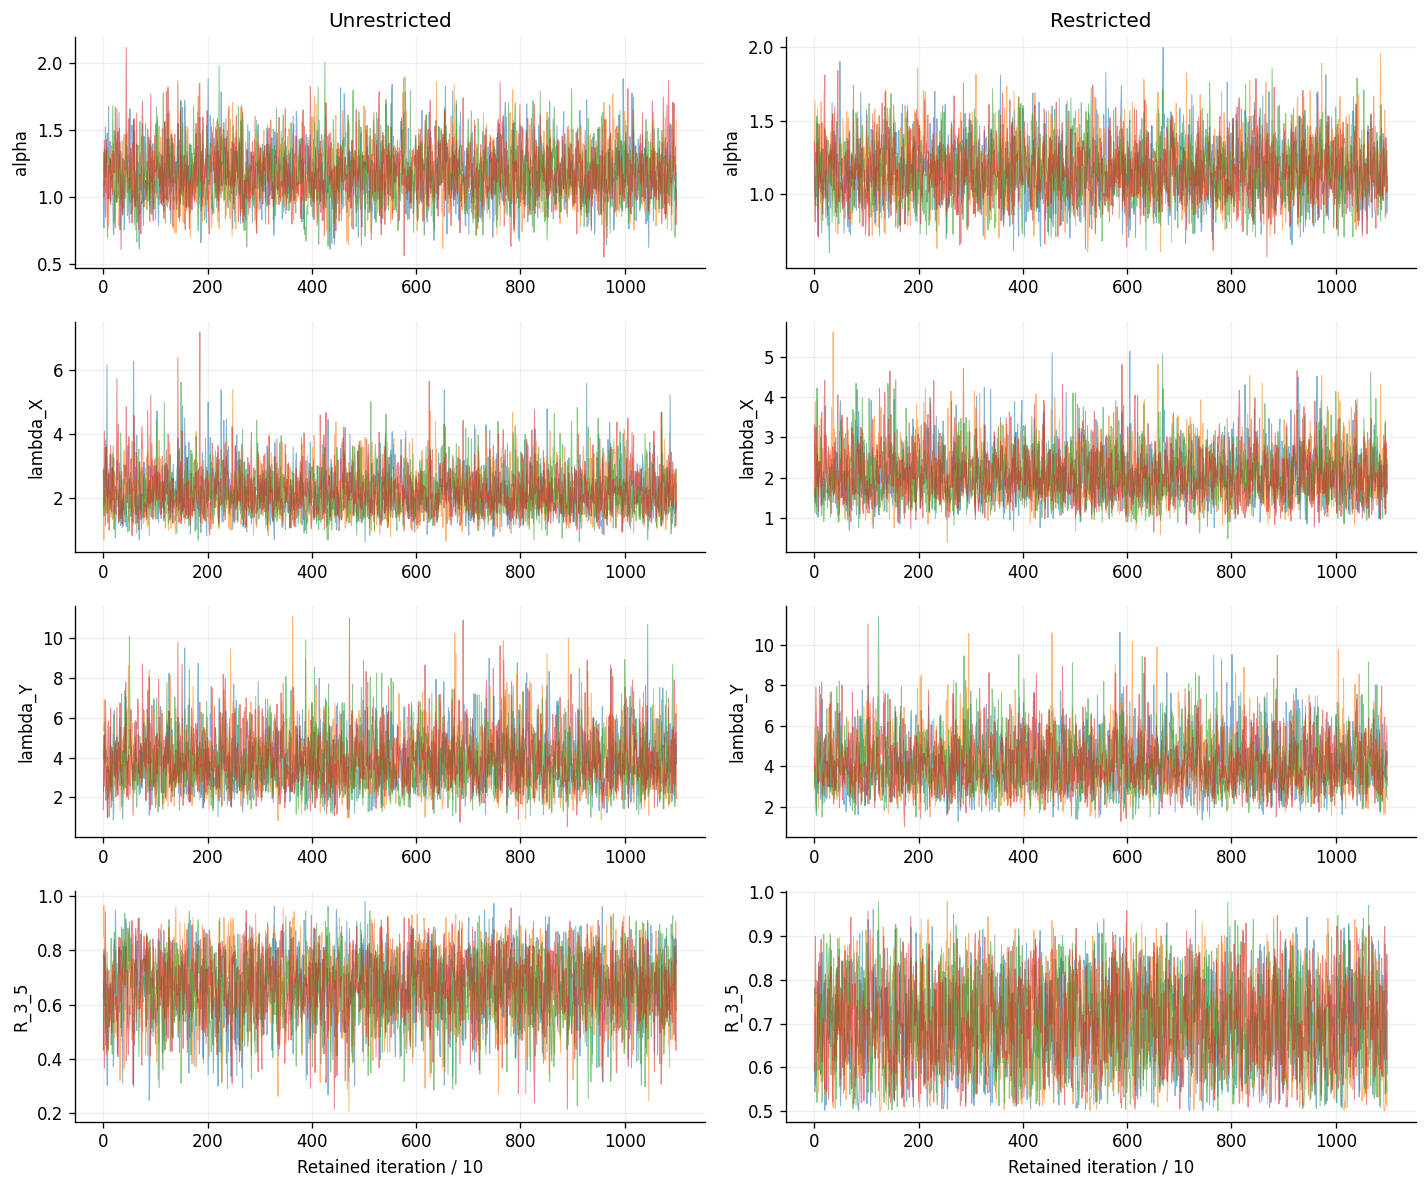

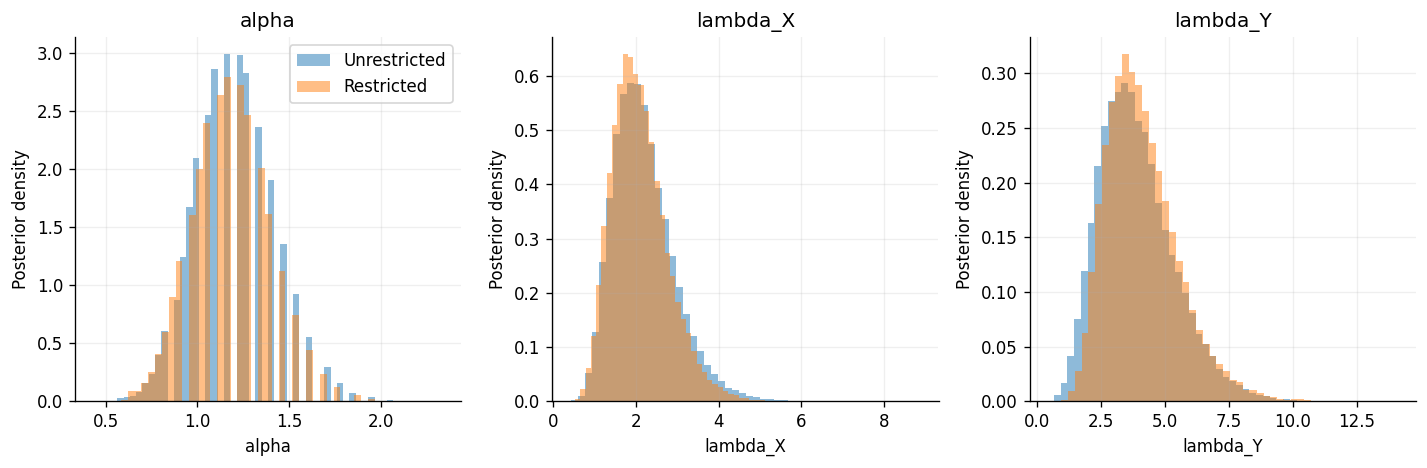

In [10]:
chain_u,accept_u=mcmc(real_data)
chain_o,accept_o=mcmc(real_data,True)
diag_u=chain_diagnostics(chain_u);diag_o=chain_diagnostics(chain_o)
diag_u['model']='Unrestricted';diag_o['model']='Restricted'
diagnostics=pd.concat([diag_u,diag_o],ignore_index=True)
diagnostics['quadrature_mean']=np.r_[gu['means'],go['means']]
diagnostics['difference']=diagnostics['mean']-diagnostics.quadrature_mean
diagnostics.to_csv(ROOT/'results/posterior_diagnostics.csv',index=False)
np.savez_compressed(ROOT/'results/posterior_chains.npz',unrestricted=chain_u,restricted=chain_o)
display(diagnostics);display(pd.DataFrame({'chain':range(1,5),'unrestricted_acceptance':accept_u,'restricted_acceptance':accept_o}))
assert diagnostics.split_Rhat.max()<1.02
assert diagnostics.ESS.min()>400
assert np.all(np.abs(diagnostics.difference)<5*diagnostics.MCSE+.002)
fig,axes=plt.subplots(4,2,figsize=(12,10))
for j,name in enumerate(PARAMETERS):
    for c in range(4):
        axes[j,0].plot(chain_u[c,::10,j],alpha=.55,linewidth=.6)
        axes[j,1].plot(chain_o[c,::10,j],alpha=.55,linewidth=.6)
    axes[j,0].set(ylabel=name,title='Unrestricted' if j==0 else None);axes[j,1].set(ylabel=name,title='Restricted' if j==0 else None)
axes[-1,0].set_xlabel('Retained iteration / 10');axes[-1,1].set_xlabel('Retained iteration / 10')
fig.tight_layout();save_figure('09_posterior_traces')
fig,axes=plt.subplots(1,3,figsize=(12,4))
for j,name in enumerate(PARAMETERS[:3]):
    axes[j].hist(posterior_u[:,j],bins=50,density=True,alpha=.5,label='Unrestricted');axes[j].hist(posterior_o[:,j],bins=50,density=True,alpha=.5,label='Restricted');axes[j].set(xlabel=name,ylabel='Posterior density',title=name)
axes[0].legend();fig.tight_layout();save_figure('10_parameter_posteriors')

## 15. Sensitivity analyses and posterior predictive checks
Hyperparameters, hybrid scheme, record order/count, and the imposed acquisition order are varied explicitly. All settings and exclusions are recorded. Posterior predictive checks regenerate the actual censored/record experiment; they do not compare dependent records to an iid empirical distribution.

,analysis,setting,restricted,R,lower,upper
0,Prior,Primary,False,0.665593,0.380472,0.894740
1,Prior,Primary,True,0.698883,0.515746,0.898782
2,Prior,Broader total rate,False,0.675694,0.388614,0.901816
3,Prior,Broader total rate,True,0.706290,0.517285,0.905304
4,Prior,More concentrated rates,False,0.619441,0.363862,0.847443
5,Prior,More concentrated rates,True,0.660940,0.510290,0.854617
6,Hybrid scheme,typeI,False,0.665593,0.380472,0.894740
7,Hybrid scheme,typeI,True,0.698883,0.515746,0.898782
8,Hybrid scheme,adaptiveII,False,0.544995,0.292417,0.786330
9,Hybrid scheme,adaptiveII,True,0.622348,0.505702,0.804701


,attempted_orders,orders_reaching_six_records,orders_not_reaching_target,mean_R,minimum_R,maximum_R
0,200,123,77,0.658735,0.602463,0.818594


,statistic,observed,predictive_lower,predictive_upper,posterior_predictive_upper_tail
0,Observed failure count,13.00000,8.000000,19.000000,0.666
1,Largest record,0.66266,0.297403,2.257265,0.651


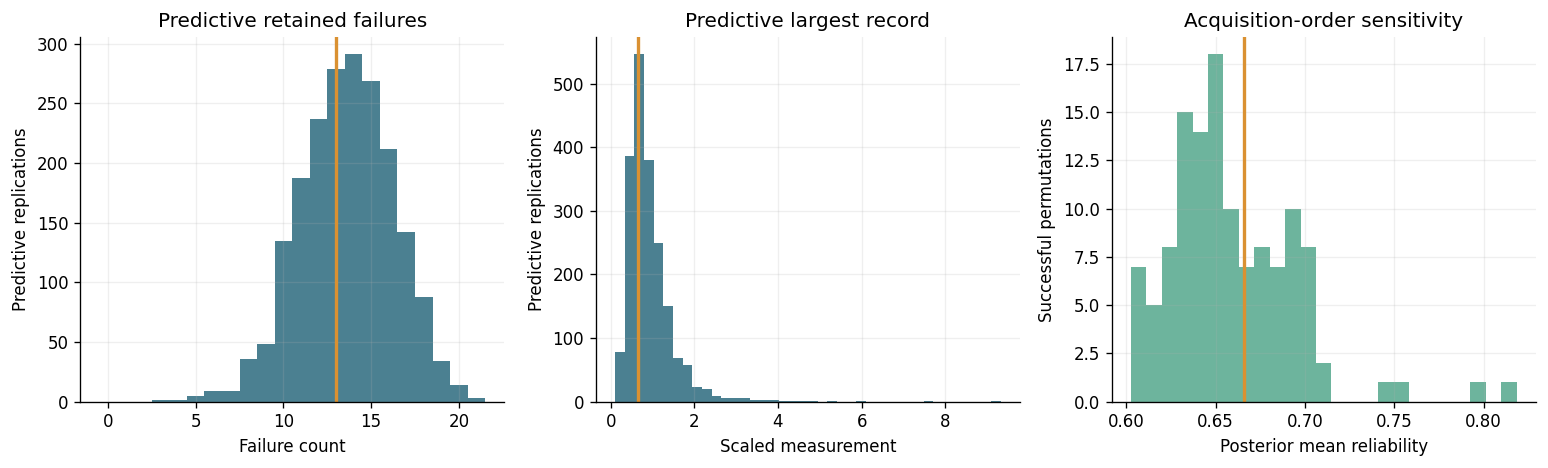

In [11]:
sensitivity=[]
priors={'Primary':PRIOR,'Broader total rate':dict(a0=1.,b0=.25,c1=2.,c2=2.,a1=1.,b1=.5),'More concentrated rates':dict(a0=6.,b0=1.5,c1=4.,c2=4.,a1=4.,b1=2.)}
for label,pr in priors.items():
    for ordered in [False,True]:
        gg=posterior_grid(real_data,ordered,pr,na=240,np_=320)
        sensitivity.append(dict(analysis='Prior',setting=label,restricted=ordered,R=gg['means'][-1],lower=gg['ci'][0],upper=gg['ci'][1]))
for mode in ['typeI','adaptiveII']:
    rr=np.random.default_rng(SEED)
    rr.permutation(np.arange(30))
    bb=[censor_block(x[ind],7,.5,removal_plan(10,7),rr,mode) for ind in partition]
    dd=make_data(bb,records,2)
    for ordered in [False,True]:
        gg=posterior_grid(dd,ordered,na=240,np_=320)
        sensitivity.append(dict(analysis='Hybrid scheme',setting=mode,restricted=ordered,R=gg['means'][-1],lower=gg['ci'][0],upper=gg['ci'][1]))
for kk,rc in [(1,4),(2,4),(2,8),(3,6)]:
    yy,ii=extract_records(y,kk,rc)
    dd=make_data(blocks,yy,kk)
    gg=posterior_grid(dd,na=240,np_=320)
    sensitivity.append(dict(analysis='Record design',setting=f'k={kk}, r={rc}',restricted=False,R=gg['means'][-1],lower=gg['ci'][0],upper=gg['ci'][1]))
sensitivity=pd.DataFrame(sensitivity)
sensitivity.to_csv(ROOT/'results/sensitivity.csv',index=False);display(sensitivity)
order_results=[];order_failures=0;rr=np.random.default_rng(SEED+60)
for rep in range(200):
    try:
        yy,ii=extract_records(rr.permutation(y),2,6)
        gg=posterior_grid(make_data(blocks,yy,2),na=110,np_=160)
        order_results.append(dict(permutation=rep+1,R=gg['means'][-1],record_stop_position=ii[-1],largest_record=yy[-1]))
    except ValueError:
        order_failures+=1
order_results=pd.DataFrame(order_results)
order_results.to_csv(ROOT/'results/acquisition_order_sensitivity.csv',index=False)
display(pd.DataFrame([dict(attempted_orders=200,orders_reaching_six_records=len(order_results),orders_not_reaching_target=order_failures,mean_R=order_results.R.mean(),minimum_R=order_results.R.min(),maximum_R=order_results.R.max())]))
rr=np.random.default_rng(SEED+61);predictive=[]
for i in range(2000):
    ash,aa,bb,_=posterior_u[rr.integers(len(posterior_u))]
    bbk=[]
    for old in blocks:
        raw=(rr.exponential(size=old['n'])/aa)**(1/ash)
        bbk.append(censor_block(raw,old['m'],old['T'],removal_plan(old['n'],old['m']),rr,old['mode']))
    yy=(np.cumsum(rr.exponential(scale=1/(2*bb),size=6)))**(1/ash)
    predictive.append(dict(failure_count=sum(len(bk['x']) for bk in bbk),largest_record=yy[-1]))
predictive=pd.DataFrame(predictive)
predictive.to_csv(ROOT/'results/posterior_predictive.csv',index=False)
ppcheck=pd.DataFrame([dict(statistic='Observed failure count',observed=real_data['d'],predictive_lower=np.quantile(predictive.failure_count,.025),predictive_upper=np.quantile(predictive.failure_count,.975),posterior_predictive_upper_tail=np.mean(predictive.failure_count>=real_data['d'])),dict(statistic='Largest record',observed=records[-1],predictive_lower=np.quantile(predictive.largest_record,.025),predictive_upper=np.quantile(predictive.largest_record,.975),posterior_predictive_upper_tail=np.mean(predictive.largest_record>=records[-1]))])
ppcheck.to_csv(ROOT/'results/predictive_checks.csv',index=False);display(ppcheck)
fig,axes=plt.subplots(1,3,figsize=(13,4))
axes[0].hist(predictive.failure_count,bins=np.arange(0,23)-.5,color='#0f566c',alpha=.75);axes[0].axvline(real_data['d'],color='#da9132',linewidth=2);axes[0].set(title='Predictive retained failures',xlabel='Failure count',ylabel='Predictive replications')
axes[1].hist(predictive.largest_record,bins=40,color='#0f566c',alpha=.75);axes[1].axvline(records[-1],color='#da9132',linewidth=2);axes[1].set(title='Predictive largest record',xlabel='Scaled measurement',ylabel='Predictive replications')
axes[2].hist(order_results.R,bins=25,color='#3c9b7d',alpha=.75);axes[2].axvline(gu['means'][-1],color='#da9132',linewidth=2);axes[2].set(title='Acquisition-order sensitivity',xlabel='Posterior mean reliability',ylabel='Successful permutations')
fig.tight_layout();save_figure('11_predictive_order_sensitivity')

## 16. Results interpretation and requirement audit

In [12]:
agg=Rsummary.groupby(['regime','method'])[['bias','mse','coverage','average_length']].mean().reset_index()
agg.to_csv(ROOT/'results/reliability_regime_summary.csv',index=False);display(agg)
real_refinement=[]
for ordered,base in [(False,gu),(True,go)]:
    gg=posterior_grid(real_data,ordered,na=400,np_=520)
    real_refinement.append(dict(restricted=ordered,maximum_mean_difference=np.max(np.abs(base['means']-gg['means'])),maximum_interval_difference=np.max(np.abs(base['ci']-gg['ci'])),edge_mass=base['edge_mass']))
real_refinement=pd.DataFrame(real_refinement)
real_refinement.to_csv(ROOT/'results/real_quadrature_refinement.csv',index=False);display(real_refinement)
assert real_refinement.maximum_mean_difference.max()<1e-4
assert real_refinement.maximum_interval_difference.max()<.002
findings=f'''The complete 15 mm and 20 mm samples give calibrated Weibull K-S p-values {gof.bootstrap_p.iloc[0]:.3f} and {gof.bootstrap_p.iloc[1]:.3f}. The common-shape likelihood-ratio statistic is {shape_test['LR']:.3f}, with bootstrap p-value {shape_test['bootstrap_p']:.3f}. The 15 mm calibrated test rejects Weibull adequacy at the 5% level, so the jute estimates are reported with a model-fit limitation. The additional carbon-fibre halves have calibrated K-S p-values {carbon_gof.bootstrap_p.iloc[0]:.3f} and {carbon_gof.bootstrap_p.iloc[1]:.3f}; their common-shape bootstrap p-value is {carbon_shape['bootstrap_p']:.3f}. These are compatible with the fitted Weibull model at this sample size, without proving it true. Their unrestricted and restricted posterior reliability means are {cgu['means'][-1]:.4f} and {cgo['means'][-1]:.4f}, respectively.

The retrospective Type-I experiment retains {real_data['d']} strength failures and {real_data['r']} upper 2-records. The unrestricted MLE reliability is {fits['MLE'][-1]:.4f}; its log-ratio 95% confidence interval is [{Raci[0]:.4f}, {Raci[1]:.4f}]. The unrestricted posterior mean is {gu['means'][-1]:.4f}, with a 95% equal-tail credible interval [{gu['ci'][0]:.4f}, {gu['ci'][1]:.4f}]. The restricted MLE is {fits['Restricted MLE'][-1]:.4f}; the restricted posterior mean is {go['means'][-1]:.4f}, with credible interval [{go['ci'][0]:.4f}, {go['ci'][1]:.4f}]. The restricted posterior excludes reliability below one half by construction, so this shift reflects the assumed rate order as well as the measurements.

Across 14,400 simulated datasets, all four estimators were compared against fixed truths and all raw outputs were retained. Scenario-level tables include Monte Carlo uncertainty. Under a false order restriction, the true reliability is below one half while restricted estimates cannot be; the resulting bias and low coverage are a structural consequence rather than an implementation error. At an equality boundary, a continuous truncated posterior has all interval mass above one half, so an equal-tail restricted credible interval need not include the boundary truth. This is why boundary coverage is reported explicitly.

The largest sampler split R-hat is {diagnostics.split_Rhat.max():.4f} and the minimum effective sample size is {diagnostics.ESS.min():.0f}. Sampler means are checked against quadrature with their Monte Carlo standard errors. The maximum real-data quadrature refinement difference in a mean is {real_refinement.maximum_mean_difference.max():.2g}. The model remains conditional on common shape, homogeneous block populations, noninformative withdrawals, shared stress and the laboratory interpretation of the comparison group. Acquisition-order sensitivity and prior sensitivity should be retained when presenting the estimates.

All five assigned requirements are implemented. The SAGE reference was available at abstract level only; full-text review of that unsupplied article remains access-limited. All five supplied PDFs were examined and their uses or exclusions are recorded in the literature review.'''
(ROOT/'reports/results_discussion.md').write_text('# Results and discussion\n\nVaidik Maheshwari (250150045) and Anant Gupta (250150004)\n\n'+findings)
display(Markdown(findings))
audit=pd.DataFrame([dict(requirement='Unrestricted and restricted MLEs',evidence='Profile derivation, independent optimization check, real-data and 48-scenario tables',status='Implemented'),dict(requirement='Joint priors',evidence='Dependent gamma-Dirichlet family, Jacobian, covariance, truncated ordered prior',status='Implemented'),dict(requirement='Unrestricted and restricted Bayes estimates',evidence='Quadrature, squared-error and LINEX, credible intervals, independent sampler',status='Implemented'),dict(requirement='Complete simulation',evidence='48 x 300 datasets; point metrics for four targets; coverage, MCSE, bootstrap subset',status='Implemented'),dict(requirement='Suitable-data validation',evidence='Published jute data; calibrated K-S/LR; fit, sampling, posterior and predictive figures',status='Implemented')])
audit.to_csv(ROOT/'results/requirements_audit.csv',index=False);display(audit)

,regime,method,bias,mse,coverage,average_length
0,boundary,Bayes,0.010118,0.011454,0.962500,0.430305
1,boundary,MLE,0.005692,0.017134,0.937917,0.453057
2,boundary,Restricted Bayes,0.107630,0.014181,0.000000,0.252915
3,boundary,Restricted MLE,0.054985,0.009719,NaN,NaN
4,ordered,Bayes,-0.028298,0.009925,0.967292,0.401501
5,ordered,MLE,-0.001950,0.013008,0.941042,0.401076
6,ordered,Restricted Bayes,-0.004412,0.005077,0.983542,0.322730
7,ordered,Restricted MLE,0.000414,0.011724,NaN,NaN
8,violated,Bayes,0.034480,0.010175,0.958750,0.385821
9,violated,MLE,0.006067,0.012629,0.940000,0.405219


,restricted,maximum_mean_difference,maximum_interval_difference,edge_mass
0,False,1.376677e-14,0.000046,6.655018e-34
1,True,7.105427e-15,0.000015,7.573782e-34


The complete 15 mm and 20 mm samples give calibrated Weibull K-S p-values 0.026 and 0.078. The common-shape likelihood-ratio statistic is 0.208, with bootstrap p-value 0.620. The 15 mm calibrated test rejects Weibull adequacy at the 5% level, so the jute estimates are reported with a model-fit limitation. The additional carbon-fibre halves have calibrated K-S p-values 0.585 and 0.101; their common-shape bootstrap p-value is 0.678. These are compatible with the fitted Weibull model at this sample size, without proving it true. Their unrestricted and restricted posterior reliability means are 0.3623 and 0.5653, respectively.

The retrospective Type-I experiment retains 13 strength failures and 6 upper 2-records. The unrestricted MLE reliability is 0.7526; its log-ratio 95% confidence interval is [0.4445, 0.9446]. The unrestricted posterior mean is 0.6656, with a 95% equal-tail credible interval [0.3805, 0.8947]. The restricted MLE is 0.7526; the restricted posterior mean is 0.6989, with credible interval [0.5157, 0.8988]. The restricted posterior excludes reliability below one half by construction, so this shift reflects the assumed rate order as well as the measurements.

Across 14,400 simulated datasets, all four estimators were compared against fixed truths and all raw outputs were retained. Scenario-level tables include Monte Carlo uncertainty. Under a false order restriction, the true reliability is below one half while restricted estimates cannot be; the resulting bias and low coverage are a structural consequence rather than an implementation error. At an equality boundary, a continuous truncated posterior has all interval mass above one half, so an equal-tail restricted credible interval need not include the boundary truth. This is why boundary coverage is reported explicitly.

The largest sampler split R-hat is 1.0009 and the minimum effective sample size is 3977. Sampler means are checked against quadrature with their Monte Carlo standard errors. The maximum real-data quadrature refinement difference in a mean is 1.4e-14. The model remains conditional on common shape, homogeneous block populations, noninformative withdrawals, shared stress and the laboratory interpretation of the comparison group. Acquisition-order sensitivity and prior sensitivity should be retained when presenting the estimates.

All five assigned requirements are implemented. The SAGE reference was available at abstract level only; full-text review of that unsupplied article remains access-limited. All five supplied PDFs were examined and their uses or exclusions are recorded in the literature review.

,requirement,evidence,status
0,Unrestricted and restricted MLEs,"Profile derivation, independent optimization c...",Implemented
1,Joint priors,"Dependent gamma-Dirichlet family, Jacobian, co...",Implemented
2,Unrestricted and restricted Bayes estimates,"Quadrature, squared-error and LINEX, credible ...",Implemented
3,Complete simulation,48 x 300 datasets; point metrics for four targ...,Implemented
4,Suitable-data validation,"Published jute data; calibrated K-S/LR; fit, s...",Implemented


## 17. Literature review and bibliography

All five supplied PDFs were processed page by page into searchable text. Relevant model, sampling, likelihood, prior, simulation and application sections were examined for the assigned project. The jute-data page was also rendered and inspected to verify transcription. The assigned spreadsheet's row 3 establishes the topic and five requirements. The notebook is a Weibull adaptation with new derivations, rather than a reproduction of a paper using another distribution.

| Source | Access and location | Distribution and sampling | Material used in this project |
|---|---|---|---|
| Newer (2025), Multicomponent stress-strength reliability analysis using the inverted exponentiated Rayleigh distribution under block adaptive type-II progressive hybrid censoring and k-records, Scientific Reports 15, 43820. DOI 10.1038/s41598-025-30570-9 | Supplied full PDF, 26 pages; publisher page verified online | Inverted exponentiated Rayleigh; block adaptive Type-II progressive hybrid strengths; upper k-record stresses | Overall combined observation structure, adaptive withdrawal protocol, reliability-estimation goals, simulation bias/MSE and uncertainty comparisons. The assigned Weibull density, correct shared-stress integral and marginal record likelihood are derived separately. |
| Sultana, Cetinkaya, Raqab and Kundu (2026), Inference for block Type-I hybrid censored Weibull populations, Communications in Statistics - Theory and Methods 55(11), 3436-3459. DOI 10.1080/03610926.2025.2579720 | Supplied full PDF, 25 pages; published online 19 November 2025 | Common-shape Weibull with distinct rates; block Type-I hybrid censoring | Main Weibull parameterization, profile estimation, pooling under rate order, dependent gamma-Dirichlet prior, ordered Bayesian analysis. Table 10 supplies the 15 mm and 20 mm jute-fibre data used here. Progressive withdrawals and upper records extend its observation scheme. |
| Newer and Alanazi (2026), Empirical Bayes and Bootstrap Inference for Multicomponent Stress-Strength Reliability Under Ordered Ranked Set Sampling, Journal of Mathematics, article 5561353. DOI 10.1155/jom/5561353 | Supplied full PDF, 17 pages; publisher full-text request was unavailable through the web tool | Generalized exponential; ordered progressive Type-II ranked-set strengths, ordered lower-record ranked-set stresses; fixed or truncated-binomial system size | Conditional common-stress reliability integral in equation (4), use of bootstrap intervals and posterior expectations of the reliability function, separation of simulation scenarios and empirical applications. Its 100 published carbon-fibre measurements provide an additional same-unit validation dataset. Random system size, ranked-set likelihoods and empirical Bayes losses are outside the assignment and are not imported. |
| Hasaballah, Tashkandy, Balogun and Bakr (2024), Statistical inference of unified hybrid censoring scheme for generalized inverted exponential distribution with application to COVID-19 data, AIP Advances 14, 045111. DOI 10.1063/5.0201467 | Supplied full PDF, 13 pages | Generalized inverted exponential under unified hybrid censoring | Supporting comparison of likelihood-based and Bayesian estimation, survival/hazard plots, asymmetric LINEX loss and interval reporting. Its unified hybrid scheme and COVID-19 measurements are not used as the Weibull project data. |
| Yeganeh, Hu, Shongwe and Koning (2025), Using the attention layer mechanism in construction of a novel ratio control chart: An application to Ethereum price prediction and automated trading strategy, Engineering Applications of Artificial Intelligence 141, 109652. DOI 10.1016/j.engappai.2024.109652 | Supplied full PDF, 24 pages | Ratios of normal random variables; attention-based process control; Ethereum moving-average ratios and backtesting | Examined and classified as unrelated to the assigned reliability likelihood. No Ethereum data, ratio distribution, control chart or attention mechanism is used. Its performance metrics are run-length/trading metrics, not stress-strength estimation MSE. |
| Kumari, Tripathi, Wang and Sinha (2025), Reliability inference for a family of inverted exponentiated distributions under block progressive Type II censoring, Proceedings of the Institution of Mechanical Engineers, Part O: Journal of Risk and Reliability 239(3), 596-608. DOI 10.1177/1748006X241247866 | Assigned reference link; publisher abstract accessible; full text not supplied and full-PDF request unavailable | Inverted exponentiated family; block progressive Type-II censoring; hierarchical Bayesian inference | Abstract-level context for block facilities and hierarchical methods only. No inaccessible theorem or implementation is claimed to have been reproduced. Full-text review of this particular reference remains access-limited. |

## Mathematical decisions after reviewing the references

The paper titles are not interchangeable: generalized exponential, generalized inverted exponential, inverted exponentiated Rayleigh and Weibull are different distributions. Weibull is selected because it is explicitly assigned to these students.

The Scientific Reports paper describes a common stress but writes an unconditional binomial success sum in equations (2.5)-(2.7). For a common random stress, components are conditionally independent given that stress, but their success indicators are dependent after integration. This project uses the conditional integral, also stated in equation (4) of the Journal of Mathematics paper, and verifies its Weibull product form by integration and direct system simulation.

The Scientific Reports paper introduces record waiting times. This project uses a clearly defined marginal record-value experiment stopped at a prescribed record count. Its correct upper k-record likelihood is k^r S(y_r)^k times the product of hazard functions. Waiting times are recorded for provenance only. They are neither discarded from a claimed waiting-time likelihood nor treated as independent exponential observations on the measurement scale.

Sultana et al. provide the relevant dependent gamma-Dirichlet family. We use a_0 different from c_1+c_2, avoiding the independent-gamma special case. With two labels, the natural restriction is strength rate<=stress rate. Symmetric Beta hyperparameters make truncation and the ordered symmetric construction agree up to the normalizing constant. The posterior is explicitly restricted instead of sorting posterior draws.

The source's stated HPD quantile endpoints resemble equal-tail endpoints. Here equal-tail credible intervals and shortest posterior intervals are computed and labelled separately. Source expressions for derivatives are independently differentiated and checked numerically; signs are not copied mechanically.

The common-shape application test has one degree of freedom for the two populations used here. Three populations would have two independent shape restrictions, regardless of a printed chi-square-one label in the source. This project calibrates its two-population test by bootstrap as well.

Carbon-fibre strengths and flood discharges in the Journal of Mathematics article have different physical units. They are not combined into a physical stress-strength probability. The jute groups provide a defensible common-unit demonstration with an explicit laboratory-comparison interpretation.

The 10 mm jute group contains a printed value 70.32383 alongside values below one. Visual inspection confirms that this is printed in the supplied PDF, rather than introduced during extraction. We use the other two complete groups and document the exclusion rather than guessing a corrected value.

## Provenance and reproducibility

The original PDFs and assignment CSV remain in the project folder. Extracted text is in sources/text. The transcribed measurement table is data/jute_fibre.csv. The notebook contains the full model, mathematical derivations and executable analysis. Reports, results and figures identify the exact settings and actual computed outcomes. Numerical simulations and retrospective censoring are explicitly distinguished from the source's original measurements.

Publisher links: [Scientific Reports](https://www.nature.com/articles/s41598-025-30570-9), [Weibull block paper](https://doi.org/10.1080/03610926.2025.2579720), [Journal of Mathematics](https://doi.org/10.1155/jom/5561353), [AIP Advances](https://doi.org/10.1063/5.0201467), [ratio control-chart paper](https://doi.org/10.1016/j.engappai.2024.109652), [SAGE block-progressive paper](https://doi.org/10.1177/1748006X241247866).

Data attribution: Xia, Z. P., Yu, J. Y., Cheng, L. D., Liu, L. F. and Wang, W. M. (2009), Study on the breaking strength of jute fibres using modified Weibull distribution, Composites Part A: Applied Science and Manufacturing 40(1), 54-59, as reproduced in Sultana et al., Table 10. The original Xia article was not supplied; the transcription is verified against the supplied secondary table.


Additional data attribution: Nichols, M. D. and Padgett, W. J. (2006), A Bootstrap Control Chart for Weibull Percentiles, Quality and Reliability Engineering International 22(2), 141-151, DOI 10.1002/qre.691, as reproduced in Newer and Alanazi (2026), section 5.1.1. The original Nichols and Padgett article was not supplied; the source for the saved transcription is the provided Journal of Mathematics PDF. Calibrated validation reveals a Weibull-fit limitation in the jute 15 mm group; the carbon dataset is included to avoid presenting a rejected fit as adequate.
